# Portfolio Construction Research

**Maintained continuation of the 2024 CQF portfolio-construction study**

This is the repository's authoritative analysis. It develops the original study into a reproducible portfolio research workflow covering Black–Litterman views, minimum-variance and tracking objectives, higher-moment utility, fractional Kelly allocation, beta-neutral betting-against-beta construction, optional Fama–French five-factor regression, chronological walk-forward evaluation, turnover, transaction costs and short-borrow costs.

The original August 2024 notebook is preserved in `research_archive/portfolio_construction_2024.ipynb` as provenance. It is not a second implementation and is not required to run this analysis. Corrections from the original study are declared in `AMENDMENTS.md`.

Run all cells from top to bottom. The active configuration requests Yahoo adjusted ETF prices through 8 October 2026. Original 2024 input settings are commented out and explicitly labelled in the configuration cell. The 49-page report is retained in `research_archive/submission_report_2024.pdf`. For deterministic offline validation, set `DATA_MODE = "synthetic"`.


The missing analyses from the supplied 213-cell notebook have been reconciled below. The final appendix maps all 127 source code cells to maintained equivalents. Core diagnostics precede portfolio comparisons; exploratory context and heuristic experiments follow **Research interpretation and next work**.

**Notebook presentation:** all portfolio/data/diagnostic calculation functions are defined in the code cells below. Saved results carry the actual data source and coverage. Unchanged 2024 factors, macro snapshots and investor views are inactive unless explicitly selected. Project-module imports are not required by this notebook; the `.py` files retain matching callable functions for tests and reuse.

## 1. Research configuration

- `DATA_MODE`: `"submission"` for the supplied frozen inputs, `"yahoo"` for a fresh download, or `"synthetic"` for a software check.
- Dates use `YYYY-MM-DD`; the end date is exclusive.
- `TRAINING_DAYS` is the minimum expanding-window history before evaluation.
- Targets are refitted at the first available observation of each calendar month.
- `TRANSACTION_COST_BPS` is charged per unit of one-way turnover.
- `ANNUAL_SHORT_BORROW_BPS` is charged daily against gross short exposure.
- `KELLY_FRACTION` scales a constrained full-Kelly solution; unused wealth stays in cash. It does not force that fraction into risky assets.
- `BAB_GROSS_LIMIT` bounds absolute long-plus-short exposure.
- `FACTOR_FILE=None` disables attribution until an updated factor file is supplied. The original file is a commented reference, not an automatic fallback.
- `INVESTOR_VIEWS=[]` uses the equilibrium prior without original 2024 views. Specify views and `VIEWS_AS_OF` to enable a declared scenario.
- `RUN_ORIGINAL_CONTEXT=False` disables the unchanged original AUM/macro snapshots. Their settings remain commented as original references.


In [1]:
# ORIGINAL 2024 SUBMISSION — unchanged historical references, inactive:
# DATA_MODE = "submission"
# END_DATE = "2024-08-23"  # Original price cache actually ends 20 August 2024.
# FACTOR_FILE = "data/F-F_Research_Data_5_Factors_2x3_monthly.csv"  # Ends June 2024.
# ORIGINAL_INFLATION_FILE = "data/Inflation-data.xlsx"  # Series ends 2023.
# ORIGINAL_CREDIT_FILE = "data/WS_GLI_csv_col.csv"  # Selected series ends 2023 Q2.
# INVESTOR_VIEWS = [("GLD", "MTUM", .15, .90), ("XLK", "XLE", .08, .70), ("SPHD", "VUG", .06, .80)]
# VIEWS_AS_OF = "2024-08-21"  # Original subjective views, not October 2026 forecasts.
# RUN_ORIGINAL_CONTEXT = True  # Explicitly opt in to the original AUM/macro appendix.

# ACTIVE OCTOBER 2026 PRICE WINDOW — Yahoo end date is exclusive.
DATA_MODE = "yahoo"
START_DATE = "2020-01-01"
END_DATE = "2026-10-09"  # Request observations through 8 October 2026.
FACTOR_FILE = None  # Supply an updated cleaned monthly file to enable factor sections.
INVESTOR_VIEWS = []  # No current views supplied: BL posterior equals its prior.
VIEWS_AS_OF = None
RUN_ORIGINAL_CONTEXT = False

# User-set model/cost assumptions below are not refreshed market observations.
ANNUAL_RISK_FREE_RATE = 0.03
MAX_WEIGHT = 0.35
TRAINING_DAYS = 504
TRANSACTION_COST_BPS = 10
ANNUAL_SHORT_BORROW_BPS = 100
KELLY_FRACTION = 0.50
BAB_GROSS_LIMIT = 2.0
FACTOR_UNIT = "percent"
RANDOM_SEED = 42

ROLLING_WINDOWS = (30, 60, 90)
RISK_AVERSIONS = (0.5, 1.0, 3.07)
KELLY_COMPARISON_FRACTIONS = (0.50, 0.66, 1.00)
# Optional extra market-context acquisition; Yahoo price mode itself needs network access.
RUN_NETWORK_CONTEXT = False
NETWORK_CONTEXT_START = "1996-01-01"


## 2. Libraries and display helpers

This notebook contains the calculation implementations, the calls that perform
the study, and their saved results. Run it top to bottom from the repository
folder with the supplied `data/` directory. No project-module import hides the
portfolio or diagnostic calculations. The Python modules provide matching
callable functions for automated tests and reuse; a parity test checks that their
calculation bodies agree with the visible notebook definitions.

In [2]:
# Third-party libraries only: all project calculations are defined below.
import hashlib
import json
import re
from datetime import datetime, timezone
from scipy.optimize import minimize
from scipy.stats import kurtosis, skew
PERIODS_PER_YEAR = 252
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


pd.set_option("display.max_columns", 30)
print("Research modules ready. Data mode:", DATA_MODE)


import numpy as np
from importlib.metadata import version
diagnostic_tables, diagnostic_figures = {}, {}
print("Package versions:", {p: version(p) for p in ["numpy", "pandas", "scipy", "yfinance"]})

def show_heatmap(frame, title, key, centered=False):
    fig, ax = plt.subplots(figsize=(max(7, len(frame.columns) * .48), max(5, len(frame) * .38)))
    values = frame.to_numpy(dtype=float)
    limit = np.nanmax(np.abs(values))
    image = ax.imshow(values, aspect="auto", cmap="coolwarm" if centered else "viridis",
                      vmin=-limit if centered else None, vmax=limit if centered else None)
    ax.set_xticks(range(len(frame.columns)), frame.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(frame.index)), frame.index)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=.8)
    fig.tight_layout()
    diagnostic_figures[key] = fig
    plt.show()
    plt.close(fig)

def show_panels(frame, title, key, ylabel):
    columns = 4
    rows = (len(frame.columns) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(15, 2.7 * rows), squeeze=False)
    for ax, name in zip(axes.flat, frame):
        ax.plot(frame.index, frame[name], linewidth=.8)
        ax.set_title(name)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", labelrotation=30)
    for ax in list(axes.flat)[len(frame.columns):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    diagnostic_figures[key] = fig
    plt.show()
    plt.close(fig)

DATA_DIR = Path("data")
ASSETS = ['VUG', 'SPHD', 'MTUM', 'ACWI', 'XLK', 'XLE', 'IEO', 'GLD']
BENCHMARK = 'SPY'
FACTOR_COLUMNS = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
INFLATION_SERIES = {
    'HCPI_GLOBAL_MED': 'Median',
    'HCPI_GLOBAL_AVE': 'Average',
    'HCPI_GLOBAL_AVE_GDP': 'GDP-weighted average',
}
BIS_SERIES = dict(FREQ='Q', CURR_DENOM='TO1', BORROWERS_CTY='5J',
                  BORROWERS_SECTOR='A', LENDERS_SECTOR='B', L_POS_TYPE='I',
                  L_INSTR='A', UNIT_MEASURE='770', UNIT_MULT='0')

Research modules ready. Data mode: yahoo
Package versions: {'numpy': '2.5.3', 'pandas': '2.3.3', 'scipy': '1.18.1', 'yfinance': '1.7.0'}


### Calculation: Input validation and frozen price data

In [3]:
def _numeric_frame(frame, name, minimum_rows=24):
    if not isinstance(frame, pd.DataFrame) or len(frame) < minimum_rows:
        raise ValueError(f'{name} must be a DataFrame with at least {minimum_rows} rows.')
    result = frame.apply(pd.to_numeric, errors='raise').copy()
    if result.index.has_duplicates:
        raise ValueError(f'{name} has duplicate dates.')
    if not np.isfinite(result.to_numpy()).all():
        raise ValueError(f'{name} must contain finite values.')
    return result.sort_index()


def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def verify_submission_files(root=None):
    """Verify imported bytes against the checked-in provenance manifest."""
    root = Path(root) if root else DATA_DIR.parent
    manifest = json.loads((root / 'data/manifest.json').read_text(encoding='utf-8'))
    for item in manifest['files']:
        path = root / item['path']
        if not path.is_file() or file_sha256(path) != item['sha256']:
            raise ValueError(f'Submission file missing or changed: {item["path"]}')
    return manifest


def load_submission_prices(path=None, symbols=None, start=None, end=None):
    """Pivot genuine adjusted closes, rejecting duplicate keys and invalid prices.

    Market Cap is a repeated snapshot, not historical market weights. It is never
    used here. A requested end is exclusive. Missing observations stay missing.
    """
    path = Path(path) if path else DATA_DIR / 'efts_dataset.csv'
    raw = pd.read_csv(path)
    required = {'Date', 'ETF', 'Adj Close'}
    if not required.issubset(raw.columns):
        raise ValueError(f'ETF cache requires columns {sorted(required)}.')
    if raw[list(required)].isna().any().any():
        raise ValueError('ETF cache contains missing keys or adjusted prices.')
    raw['Date'] = pd.to_datetime(raw['Date'], errors='raise')
    if raw.duplicated(['Date', 'ETF']).any():
        raise ValueError('ETF cache contains duplicate (Date, ETF) observations.')
    raw['Adj Close'] = pd.to_numeric(raw['Adj Close'], errors='raise')
    if not np.isfinite(raw['Adj Close']).all() or (raw['Adj Close'] <= 0).any():
        raise ValueError('Adjusted prices must be finite and positive.')
    prices = raw.pivot(index='Date', columns='ETF', values='Adj Close').sort_index()
    if symbols is not None:
        missing = set(symbols) - set(prices.columns)
        if missing:
            raise ValueError(f'ETF cache is missing symbols: {sorted(missing)}')
        prices = prices.loc[:, list(symbols)]
    if start is not None:
        prices = prices.loc[prices.index >= pd.Timestamp(start)]
    if end is not None:
        prices = prices.loc[prices.index < pd.Timestamp(end)]
    if prices.empty:
        raise ValueError('No submission prices in the requested date range.')
    prices.columns.name = None
    return prices

### Calculation: Price acquisition and within-asset returns

In [4]:
def load_prices(mode='synthetic', start='2020-01-01', end='2024-08-23', seed=42,
                cache_path=None):
    """Return a date-by-symbol table and provenance; never silently change mode."""
    start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
    if pd.isna(start_date) or pd.isna(end_date) or start_date >= end_date:
        raise ValueError('START_DATE must be earlier than END_DATE; use YYYY-MM-DD.')
    symbols = ASSETS + [BENCHMARK]
    if mode in {'synthetic', 'demo'}:
        dates = pd.bdate_range(start_date, end_date, inclusive='left')
        if len(dates) < 253:
            raise ValueError('Choose at least 253 business days for this example.')
        rng = np.random.default_rng(seed)
        market = rng.normal(0.00025, 0.01, len(dates))
        common = rng.normal(0, 0.004, len(dates))
        beta = np.array([1.1, 0.65, 0.95, 0.85, 1.25, 0.9, 1.0, 0.1])
        drift = np.array([.00005, .00001, .00004, .00001, .00008, .00002, .00001, .00003])
        noise = rng.normal(0, 0.006, (len(dates), len(ASSETS)))
        log_returns = market[:, None] * beta + common[:, None] + drift + noise
        levels = np.column_stack([100 * np.exp(np.cumsum(log_returns, axis=0)),
                                  100 * np.exp(np.cumsum(market))])
        prices = pd.DataFrame(levels, index=dates, columns=symbols)
        mode = 'synthetic'
        label = 'SYNTHETIC VALIDATION DATA - not real ETF performance'
        details = {'seed': seed, 'calendar': 'weekdays, including market holidays'}
    elif mode == 'submission':
        path = Path(cache_path) if cache_path else DATA_DIR / 'efts_dataset.csv'
        prices = load_submission_prices(path, symbols, start, end)
        label = 'SUBMISSION SNAPSHOT - adjusted ETF prices supplied with the 2024 study'
        details = {'source_file': path.name, 'source_file_sha256': file_sha256(path),
                   'price_field': 'Adj Close', 'aum_used': False,
                   'vintage': '2024 submission; exact provider download timestamp unknown'}
    elif mode == 'yahoo':
        import yfinance as yf
        try:
            raw = yf.download(symbols, start=start, end=end, auto_adjust=True,
                              progress=False, threads=False, timeout=30,
                              multi_level_index=True)
        except Exception as exc:
            raise RuntimeError('Yahoo download failed. Check your internet connection, '
                               'or explicitly change DATA_MODE to "synthetic".') from exc
        if raw is None or raw.empty or 'Close' not in raw:
            raise ValueError('Yahoo returned no usable prices. Try again later or choose DATA_MODE="synthetic".')
        prices = raw['Close'].copy()
        missing = set(symbols) - set(prices.columns)
        if missing:
            raise ValueError(f'Yahoo did not return these symbols: {sorted(missing)}. No substitute data were used.')
        prices = prices.reindex(columns=symbols)
        prices.index = pd.to_datetime(prices.index).tz_localize(None)
        label = 'YAHOO FINANCE - adjusted historical prices, downloaded now'
        details = {'auto_adjust': True, 'downloaded_utc': datetime.now(timezone.utc).isoformat()}
    else:
        raise ValueError('DATA_MODE must be "submission", "synthetic" or "yahoo".')

    prices = prices.sort_index()
    if prices.index.has_duplicates:
        raise ValueError('Duplicate price dates: review the source before continuing.')
    prices = prices.apply(pd.to_numeric, errors='raise')
    finite_prices = prices.to_numpy()[np.isfinite(prices.to_numpy())]
    if (finite_prices <= 0).any() or np.isinf(prices.to_numpy()).any():
        raise ValueError('Prices must be positive finite numbers or missing observations.')
    if prices.notna().sum().min() < 253:
        raise ValueError('At least one symbol has fewer than 253 prices. Expand the date range.')
    prices.index.name = 'Date'
    provenance = {
        'mode': mode, 'label': label, 'requested_start': start, 'requested_end_exclusive': end,
        'first_price': str(prices.index.min().date()), 'last_price': str(prices.index.max().date()),
        'price_rows': len(prices), 'symbols': symbols,
        'missing_prices_by_symbol': prices.isna().sum().astype(int).to_dict(),
        'prices_csv_sha256': hashlib.sha256(prices.to_csv().encode('utf-8')).hexdigest(),
        **details,
    }
    return prices, provenance


def aligned_returns(prices):
    """Trim unavailable endpoints and reject gaps inside the common price history.

    Dropping an internal return row would erase held assets' gains/losses. This
    function does not invent prices or an exchange calendar for absent dates.
    """
    if not isinstance(prices.index, pd.DatetimeIndex) or prices.index.has_duplicates:
        raise ValueError('Prices require unique datetime observations.')
    prices = prices.sort_index()
    if prices.columns.has_duplicates or prices.empty or prices.isna().all().any():
        raise ValueError('Price columns must be unique and contain observations.')
    start = max(prices.apply(lambda x: x.first_valid_index()))
    end = min(prices.apply(lambda x: x.last_valid_index()))
    common = prices.loc[start:end]
    if common.isna().any().any():
        raise ValueError('Internal missing prices: repair the source or define an explicit valuation policy; return days cannot be dropped.')
    if not np.isfinite(common.to_numpy()).all() or (common <= 0).any().any():
        raise ValueError('Prices must be finite and positive.')
    returns = common.pct_change(fill_method=None).iloc[1:]
    if len(returns) < 252:
        raise ValueError('Fewer than 252 complete aligned return observations. Expand the dates or inspect gaps.')
    if not np.isfinite(returns.to_numpy()).all():
        raise ValueError('Returns contain non-finite values.')
    if (returns <= -1).any().any():
        raise ValueError('A simple return is at or below -100%; inspect the price data.')
    return returns

## 3. Acquire and validate prices

The analysis uses a date-by-symbol adjusted-price table, so returns are calculated within each asset and never across symbol boundaries. Yahoo failures stop the run instead of substituting synthetic observations. The source mode, requested dates, coverage and price-table SHA-256 hash are recorded with every output.

Submission mode reads `Adj Close` from the original 24,486-row ETF cache. It validates duplicate date/symbol keys and prices before pivoting. It never uses the repeated AUM snapshot as a historical series. The actual file ends on 20 August 2024; requesting a later end does not fabricate further observations.


In [5]:
if DATA_MODE == "submission":
    manifest = verify_submission_files()
prices, provenance = load_prices(DATA_MODE, START_DATE, END_DATE, RANDOM_SEED)
if DATA_MODE == "submission":
    provenance["submission_input_hashes"] = {f["path"]: f["sha256"] for f in manifest["files"]}
print(provenance["label"])
print(f"{len(prices):,} price rows, {prices.shape[1]} asset labels")
print("First date:", provenance["first_price"], "| Last date:", provenance["last_price"])
display(prices.head().round(2))


YAHOO FINANCE - adjusted historical prices, downloaded now
1,701 price rows, 9 asset labels
First date: 2020-01-02 | Last date: 2026-10-08


Ticker,VUG,SPHD,MTUM,ACWI,XLK,XLE,IEO,GLD,SPY
Date,,,,,,,,,
2020-01-02,29.60,32.93,117.35,71.71,44.19,23.05,45.52,143.95,295.39
2020-01-03,29.40,32.86,117.33,71.09,43.69,22.98,45.51,145.86,293.15
2020-01-06,29.59,32.93,117.46,71.25,43.80,23.16,46.06,147.39,294.27
2020-01-07,29.58,32.81,117.17,71.07,43.78,23.10,46.45,147.97,293.45
2020-01-08,29.81,32.86,117.79,71.42,44.25,22.72,45.24,146.86,295.01


### Calculation: Performance statistics and benchmark comparison

In [6]:
def historical_metrics(series, annual_rf=0.03, periods_per_year=PERIODS_PER_YEAR):
    """Annualized metrics from explicit period frequency; default is daily/252."""
    values = np.asarray(series, dtype=float)
    if len(values) < 2 or not np.isfinite(values).all() or (values <= -1).any():
        raise ValueError('At least two finite period returns above -100% are required.')
    if not np.isfinite(annual_rf) or annual_rf <= -1:
        raise ValueError('The annual risk-free assumption must be finite and greater than -100%.')
    if not np.isfinite(periods_per_year) or periods_per_year <= 0:
        raise ValueError('periods_per_year must be positive.')
    volatility = values.std(ddof=1) * np.sqrt(periods_per_year)
    excess = values - ((1 + annual_rf) ** (1 / periods_per_year) - 1)
    downside = np.sqrt(np.mean(np.minimum(excess, 0) ** 2) * periods_per_year)
    wealth = np.concatenate([[1.0], np.cumprod(1 + values)])
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    return {
        'Annual mean': values.mean() * periods_per_year,
        'CAGR': wealth[-1] ** (periods_per_year / len(values)) - 1,
        'Annual volatility': volatility,
        'Sharpe': excess.mean() * periods_per_year / volatility if volatility > 0 else np.nan,
        'Sortino': excess.mean() * periods_per_year / downside if downside > 0 else np.nan,
        'Max drawdown': drawdown.min(),
    }


def performance_table(returns, annual_rf=0.03, periods_per_year=252, benchmark=None):
    data = _numeric_frame(returns, 'returns', minimum_rows=2)
    table = pd.DataFrame({name: historical_metrics(data[name], annual_rf, periods_per_year)
                          for name in data}).T
    if benchmark is not None:
        reference = pd.Series(benchmark).reindex(data.index)
        if not np.isfinite(reference.to_numpy()).all():
            raise ValueError('Benchmark dates must cover returns.')
        active = data.sub(reference, axis=0)
        table['Tracking error'] = active.std(ddof=1) * np.sqrt(periods_per_year)
        table['Information ratio'] = (active.mean() * periods_per_year
                                      / table['Tracking error'].replace(0, np.nan))
    return table

## Universe, data quality and historical diagnostics

Submission mode retains all 21 ETFs; the allocation universe remains the eight
retrospectively selected assets. Other modes diagnose the nine loaded symbols.
Internal missing prices now stop the analysis: dropping return dates can erase
real gains and losses. Leading/trailing unavailable history is trimmed to common
coverage. Entire missing exchange sessions cannot be detected without a calendar.

Initial-training statistics, CAPM fits and correlations use only the first
`TRAINING_DAYS` observations. Full-history growth and drawdown charts are descriptive
and do not choose the eight assets. The outlier table flags absolute daily moves
over 10% for inspection, without deleting or winsorizing them. Sortino uses the
root mean squared shortfall below the period cash rate over **all** observations.

,First price,Last price,Observations,Missing prices,Role
Ticker,,,,,
VUG,2020-01-02,2026-10-08,1701,0,Allocation
SPHD,2020-01-02,2026-10-08,1701,0,Allocation
MTUM,2020-01-02,2026-10-08,1701,0,Allocation
ACWI,2020-01-02,2026-10-08,1701,0,Allocation
XLK,2020-01-02,2026-10-08,1701,0,Allocation
XLE,2020-01-02,2026-10-08,1701,0,Allocation
IEO,2020-01-02,2026-10-08,1701,0,Allocation
GLD,2020-01-02,2026-10-08,1701,0,Allocation
SPY,2020-01-02,2026-10-08,1701,0,Benchmark


Initial training through: 2021-12-31


,Annual mean,CAGR,Annual volatility,Sharpe,Sortino,Max drawdown,Tracking error,Information ratio
XLK,0.3708,0.3782,0.3151,1.0831,1.5509,-0.3115,0.1158,1.1450
VUG,0.3217,0.3269,0.2773,1.0536,1.4629,-0.3178,0.0842,0.9922
SPY,0.2382,0.2285,0.2535,0.8230,1.1320,-0.3372,0.0000,NaN
MTUM,0.2348,0.2113,0.2928,0.7009,0.9800,-0.3408,0.1251,-0.0272
ACWI,0.1861,0.1689,0.2435,0.6427,0.8633,-0.3353,0.0471,-1.1071
GLD,0.1002,0.0898,0.1685,0.4193,0.5689,-0.1877,0.2816,-0.4900
IEO,0.2322,0.0848,0.5448,0.3720,0.5279,-0.6636,0.4217,-0.0142
SPHD,0.1050,0.0624,0.2972,0.2540,0.3479,-0.4139,0.1492,-0.8925
XLE,0.1259,0.0113,0.4763,0.2023,0.2851,-0.6060,0.3433,-0.3271


Absolute daily moves above 10%: 32


Daily simple return
Date       ETF                      
2020-03-09 XLE             -0.201412
           IEO             -0.259186
2020-03-12 SPHD            -0.114076
           XLE             -0.124740
           IEO             -0.137324
2020-03-13 XLK              0.117319
           IEO              0.121088
2020-03-16 VUG             -0.126153
           SPHD            -0.120303
           MTUM            -0.123652
           ACWI            -0.112152
           XLK             -0.138140
           XLE             -0.136067
           IEO             -0.129450
           SPY             -0.109424
2020-03-18 XLE             -0.143571
2020-03-24 MTUM             0.106463
           XLK              0.102415
           XLE              0.160373
           IEO              0.145195
2020-04-17 XLE              0.106224
           IEO              0.119736
2020-04-29 IEO              0.111807
2020-11-09 XLE              0.142758
           IEO              0.159953

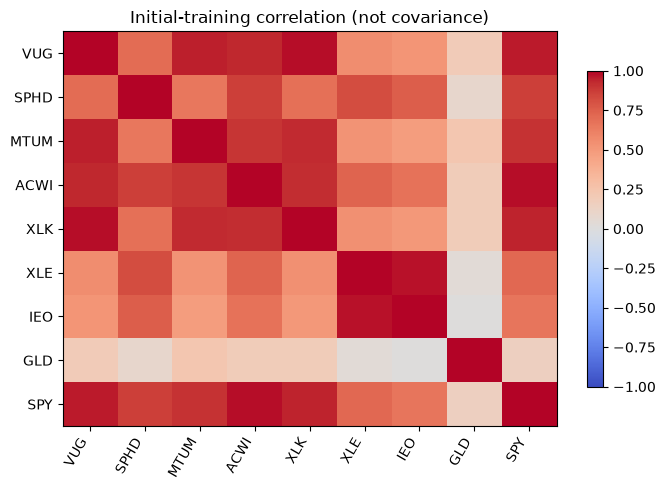

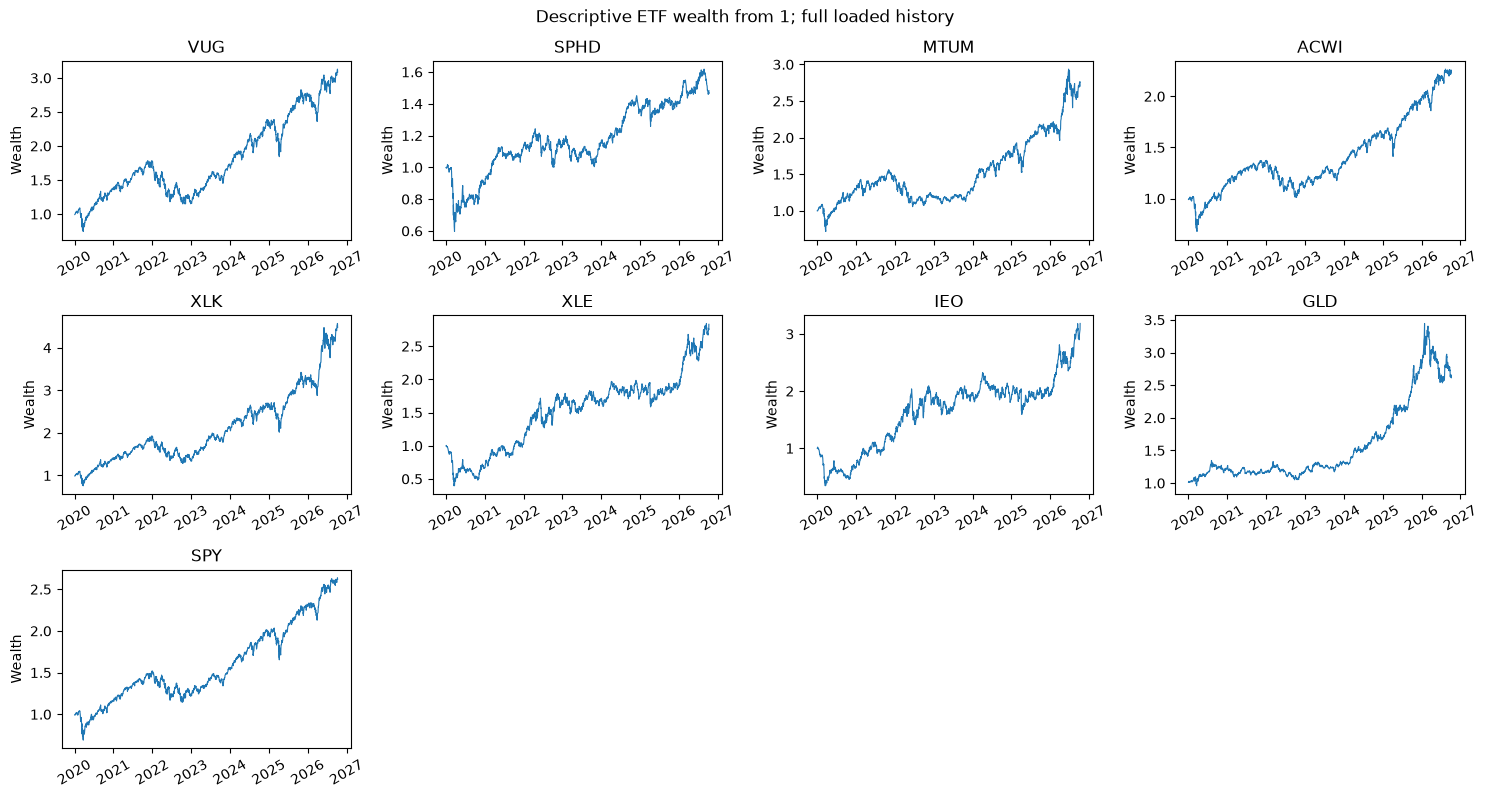

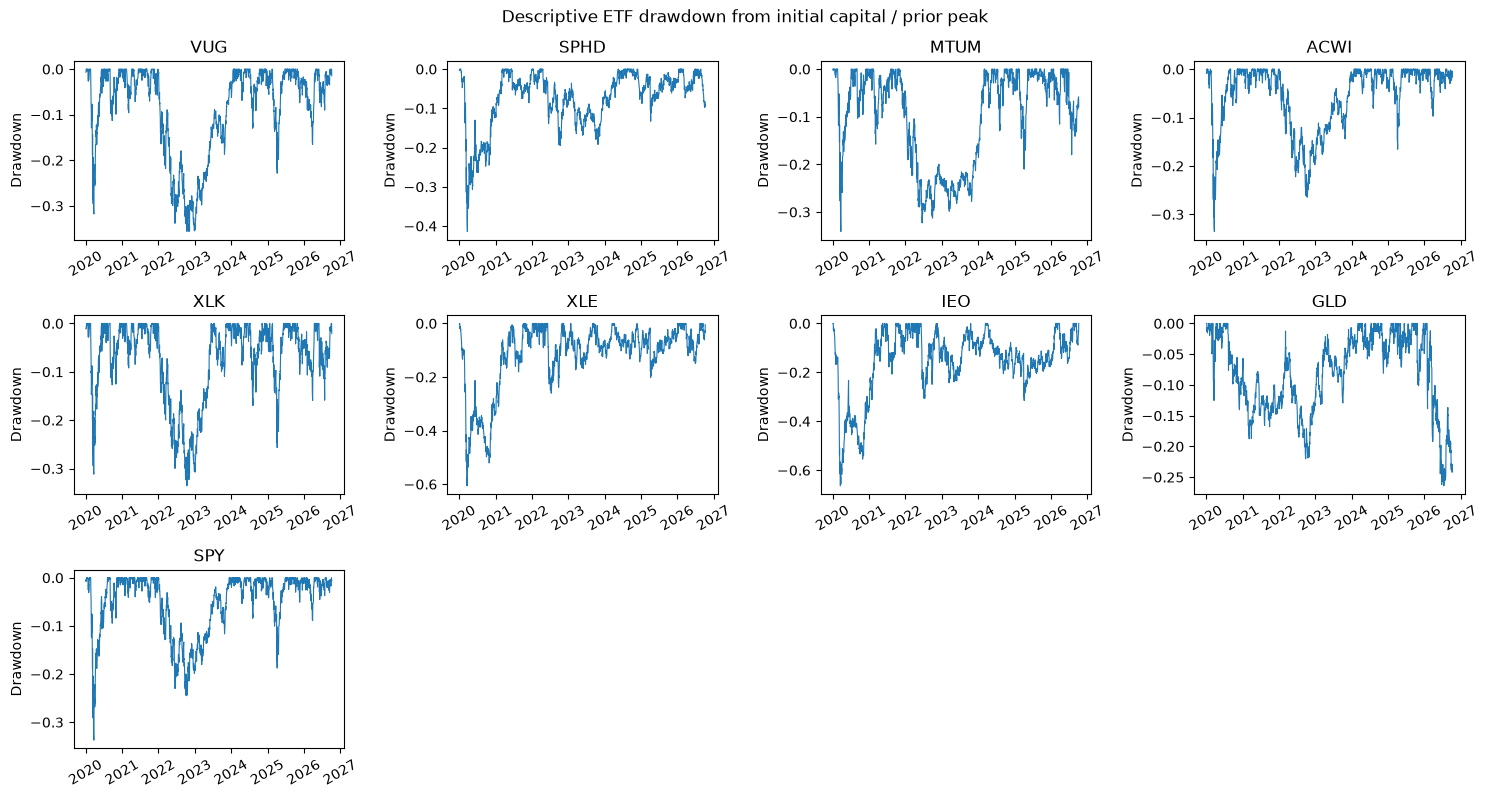

In [7]:
universe_prices = load_submission_prices(start=START_DATE, end=END_DATE) if DATA_MODE == "submission" else prices.copy()
universe_daily = aligned_returns(universe_prices)
universe_summary = pd.DataFrame({
    "First price": universe_prices.apply(lambda s: s.first_valid_index().date()),
    "Last price": universe_prices.apply(lambda s: s.last_valid_index().date()),
    "Observations": universe_prices.count(),
    "Missing prices": universe_prices.isna().sum(),
    "Role": ["Allocation" if s in ASSETS else "Benchmark" if s == BENCHMARK else "Wider study universe" for s in universe_prices],
})
initial_universe = universe_daily.iloc[:TRAINING_DAYS]
initial_performance = performance_table(initial_universe, ANNUAL_RISK_FREE_RATE, benchmark=initial_universe[BENCHMARK])
universe_correlation = initial_universe.corr()
outliers = universe_daily.where(universe_daily.abs() > .10).stack().rename("Daily simple return").to_frame()
outliers.index.names = ["Date", "ETF"]
display(universe_summary)
print("Initial training through:", initial_universe.index[-1].date())
display(initial_performance.sort_values("Sharpe", ascending=False).round(4))
print("Absolute daily moves above 10%:", len(outliers))
display(outliers.head(25))
diagnostic_tables.update(universe_coverage=universe_summary, initial_asset_performance=initial_performance,
                         universe_training_correlation=universe_correlation, flagged_daily_moves=outliers,
                         universe_training_covariance=initial_universe.cov() * 252)
show_heatmap(universe_correlation, "Initial-training correlation (not covariance)", "universe_correlation", centered=True)
growth = (1 + universe_daily).cumprod()
drawdowns = growth / growth.cummax().clip(lower=1) - 1
show_panels(growth, "Descriptive ETF wealth from 1; full loaded history", "universe_growth", "Wealth")
show_panels(drawdowns, "Descriptive ETF drawdown from initial capital / prior peak", "universe_drawdowns", "Drawdown")

### Calculation: CAPM estimation against an aligned market proxy

In [8]:
def capm_diagnostics(returns, benchmark, annual_rf=0.03):
    """OLS on matching daily excess returns; cash rate is an explicit assumption."""
    data = _numeric_frame(returns, 'returns', minimum_rows=24)
    market = pd.Series(benchmark).reindex(data.index)
    if not np.isfinite(market.to_numpy()).all() or market.var() <= 0:
        raise ValueError('Market must be finite, aligned and have positive variance.')
    rf = (1 + annual_rf) ** (1 / 252) - 1
    beta = data.apply(lambda x: x.cov(market) / market.var())
    alpha = (data.mean() - rf) - beta * (market.mean() - rf)
    return pd.DataFrame({'Beta': beta, 'Annual alpha': alpha * 252,
                         'Historical annual excess': (data.mean() - rf) * 252,
                         'CAPM annual excess': beta * (market.mean() - rf) * 252,
                         'R-squared': data.apply(lambda x: x.corr(market) ** 2),
                         'Observations': len(data)})

### Calculation: Rolling regressions and training-window selection

In [9]:
def rolling_market_model(returns, benchmark, window=60, annual_rf=0.03):
    """Trailing excess-return OLS coefficients shifted one observation forward."""
    data = _numeric_frame(returns, 'returns', minimum_rows=window + 1)
    market = pd.Series(benchmark).reindex(data.index)
    if not isinstance(window, int) or window < 3 or not np.isfinite(market).all():
        raise ValueError('Window and benchmark are invalid.')
    rf = (1 + annual_rf) ** (1 / 252) - 1
    x, y = market - rf, data - rf
    variance = x.rolling(window).var().replace(0, np.nan)
    beta = y.apply(lambda s: s.rolling(window).cov(x) / variance).shift(1)
    alpha = y.rolling(window).mean().shift(1) - beta.mul(x.rolling(window).mean().shift(1), axis=0)
    # Conditional on the realized market return; this is not an ex-ante return forecast.
    fitted = alpha + beta.mul(x, axis=0)
    return {'beta': beta, 'annual_alpha': alpha * 252,
            'conditional_excess': fitted}


def select_rolling_window(training_returns, benchmark, windows=(30, 60, 90), annual_rf=0.03):
    """Compare conditional return residuals on identical training-only dates."""
    data = _numeric_frame(training_returns, 'training_returns', minimum_rows=max(windows) + 2)
    rf = (1 + annual_rf) ** (1 / 252) - 1
    common = data.index[max(windows):]
    rows = []
    for window in windows:
        fitted = rolling_market_model(data, benchmark, window, annual_rf)['conditional_excess'].loc[common]
        if not np.isfinite(fitted.to_numpy()).all():
            raise ValueError('A candidate rolling regression has a zero-variance market window.')
        errors = data.loc[common] - rf - fitted
        rows.append({'Window': window, 'Conditional return MSE': float(np.mean(errors.to_numpy() ** 2)),
                     'Dates': len(common), 'Assets': data.shape[1],
                     'First scored date': str(common.min().date()),
                     'Last scored date': str(common.max().date())})
    scores = pd.DataFrame(rows).set_index('Window')
    return int(scores['Conditional return MSE'].idxmin()), scores

## Rolling market exposure and CAPM

For each 30/60/90-observation candidate, coefficients at date *t* use observations
strictly before *t*. Window selection compares **return residuals** on identical
initial-training dates; it does not compare beta coefficients with market returns.
The conditional fitted return uses that day's realized SPY return, so this is a
diagnostic fit score, not an implementable return forecast. The selected window is
then fixed for subsequent rolling diagnostics. Daily alpha is multiplied by 252.

SPY and ACWI CAPM examples each estimate beta against their own market proxy.
Current Yahoo beta metadata is confined to the optional appendix.

Selected on initial training only: 30


,Conditional return MSE,Dates,Assets,First scored date,Last scored date
Window,,,,,
30,0.000156,414,8,2020-05-13,2021-12-31
60,0.000158,414,8,2020-05-13,2021-12-31
90,0.000158,414,8,2020-05-13,2021-12-31


,Beta,Annual alpha,Historical annual excess,CAPM annual excess,R-squared,Observations
Ticker,,,,,,
VUG,1.0431,0.0745,0.2922,0.2176,0.9094,504
SPHD,1.0138,-0.1360,0.0755,0.2115,0.7480,504
MTUM,1.0453,-0.0128,0.2052,0.2181,0.8189,504
ACWI,0.9442,-0.0405,0.1565,0.1970,0.9660,504
XLK,1.1680,0.0976,0.3413,0.2437,0.8832,504
XLE,1.3482,-0.1849,0.0963,0.2813,0.5149,504
IEO,1.4259,-0.0948,0.2027,0.2975,0.4402,504
GLD,0.1038,0.0490,0.0707,0.0217,0.0244,504


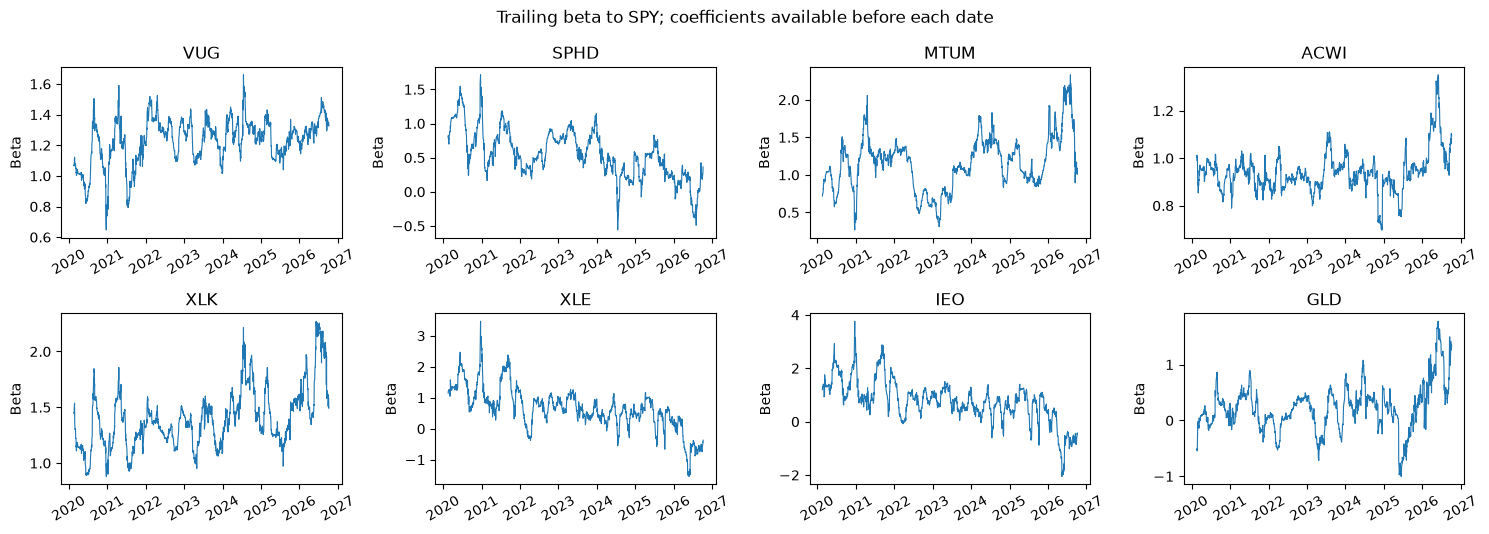

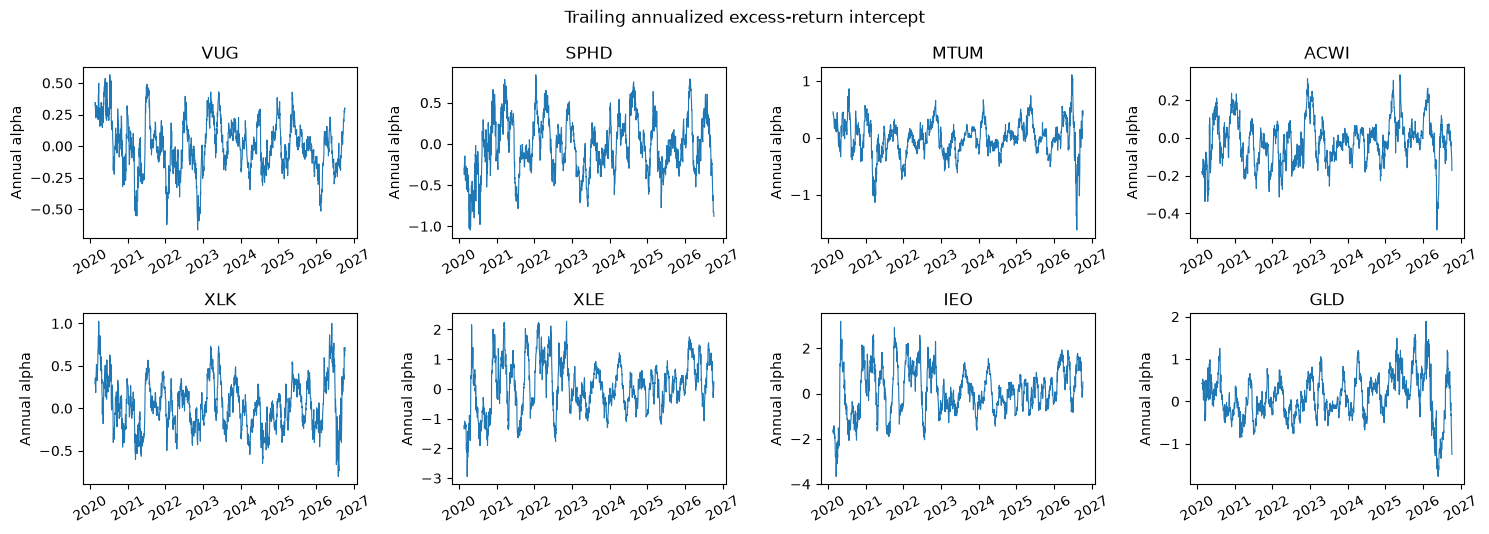

In [10]:
candidate_names = [name for name in universe_daily if name != BENCHMARK]
best_window, window_scores = select_rolling_window(
    initial_universe[candidate_names], initial_universe[BENCHMARK], ROLLING_WINDOWS, ANNUAL_RISK_FREE_RATE)
print("Selected on initial training only:", best_window)
display(window_scores)
rolling = rolling_market_model(universe_daily[candidate_names], universe_daily[BENCHMARK], best_window, ANNUAL_RISK_FREE_RATE)
capm_spy = capm_diagnostics(initial_universe[candidate_names], initial_universe[BENCHMARK], ANNUAL_RISK_FREE_RATE)
capm_acwi = capm_diagnostics(initial_universe[candidate_names], initial_universe["ACWI"], ANNUAL_RISK_FREE_RATE)
display(capm_spy.round(4))
diagnostic_tables.update(rolling_window_scores=window_scores, rolling_betas=rolling["beta"],
                         rolling_annual_alphas=rolling["annual_alpha"], initial_capm_spy=capm_spy,
                         initial_capm_acwi=capm_acwi)
show_panels(rolling["beta"], "Trailing beta to SPY; coefficients available before each date", "rolling_betas", "Beta")
show_panels(rolling["annual_alpha"], "Trailing annualized excess-return intercept", "rolling_alphas", "Annual alpha")

### Calculation: Black–Litterman prior, views and posterior

In [11]:
def black_litterman(covariance, prior_weights=None, risk_aversion=3.07, tau=0.1,
                    return_details=False, views=None):
    """Annual excess-return posterior, using view-scaled uncertainty."""
    names = list(covariance.columns)
    if names != list(covariance.index) or len(names) < 2:
        raise ValueError('Covariance labels and ordering must match.')
    sigma = covariance.to_numpy(dtype=float)
    if not np.isfinite(sigma).all() or not np.allclose(sigma, sigma.T):
        raise ValueError('Covariance must be finite and symmetric.')
    if np.linalg.eigvalsh(sigma).min() < -1e-10:
        raise ValueError('Covariance must be positive semidefinite.')
    if tau <= 0 or risk_aversion <= 0:
        raise ValueError('tau and risk aversion must be positive.')
    weights = np.full(len(names), 1 / len(names)) if prior_weights is None else np.asarray(prior_weights, dtype=float)
    if weights.shape != (len(names),) or not np.isfinite(weights).all() or (weights < 0).any() or not np.isclose(weights.sum(), 1):
        raise ValueError('Prior weights must be finite, nonnegative and sum to one.')
    # ORIGINAL 2024 SUBMISSION views (21 August 2024); inactive reference only:
    # views = [('GLD', 'MTUM', .15, .90), ('XLK', 'XLE', .08, .70), ('SPHD', 'VUG', .06, .80)]
    views = [] if views is None else list(views)
    for view in views:
        if (len(view) != 4 or view[0] not in names or view[1] not in names
                or view[0] == view[1] or not np.isfinite(view[2:]).all()
                or not 0 < view[3] <= 1):
            raise ValueError('Views require two different known assets, a finite annual difference and confidence in (0, 1].')
    p = np.zeros((len(views), len(names)))
    for j, (long_asset, short_asset, _, _) in enumerate(views):
        p[j, names.index(long_asset)] = 1
        p[j, names.index(short_asset)] = -1
    q = np.array([view[2] for view in views])
    confidence = np.array([view[3] for view in views])
    prior = risk_aversion * sigma @ weights
    scaled = tau * sigma
    view_variance = np.diag(p @ scaled @ p.T)
    omega = np.diag(np.maximum(view_variance, 1e-12) * (1 - confidence) / confidence)
    posterior = prior + scaled @ p.T @ np.linalg.solve(p @ scaled @ p.T + omega, q - p @ prior)
    table = pd.DataFrame(views, columns=['Outperformer', 'Comparator', 'Annual difference', 'Assumed confidence'])
    if return_details:
        mean_covariance = scaled - scaled @ p.T @ np.linalg.solve(p @ scaled @ p.T + omega, p @ scaled)
        labels = [f'{v[0]} - {v[1]}' for v in views]
        return {
            'prior': pd.Series(prior, index=names),
            'posterior': pd.Series(posterior, index=names), 'views': table,
            'P': pd.DataFrame(p, index=labels, columns=names),
            'Q': pd.Series(q, index=labels, name='Annual relative view'),
            'Omega': pd.DataFrame(omega, index=labels, columns=labels),
            'mean_covariance': pd.DataFrame(mean_covariance, index=names, columns=names),
            'predictive_covariance': pd.DataFrame(sigma + mean_covariance, index=names, columns=names),
        }
    return pd.Series(prior, index=names), pd.Series(posterior, index=names), table

### Calculation: Variance, Sharpe and tracking-error objectives

In [12]:
def optimize_weights(expected_excess, covariance, returns, benchmark, cap=0.35):
    """Long-only, fully invested examples, with checked solver results."""
    names = list(covariance.columns)
    if list(covariance.index) != names or list(expected_excess.index) != names or list(returns.columns) != names:
        raise ValueError('All asset labels must use the same ordering.')
    if not returns.index.equals(benchmark.index):
        raise ValueError('Asset and benchmark dates must match.')
    n = len(names)
    if not 1 / n <= cap <= 1:
        raise ValueError(f'With {n} assets, MAX_WEIGHT must be between {1/n:.3f} and 1.')
    sigma = covariance.to_numpy(dtype=float)
    mu = expected_excess.to_numpy(dtype=float)
    history = returns.to_numpy(dtype=float)
    bench = benchmark.to_numpy(dtype=float)
    if not all(np.isfinite(value).all() for value in [sigma, mu, history, bench]):
        raise ValueError('Optimization inputs must be finite.')
    equal = np.full(n, 1 / n)

    def variance(w):
        return float(w @ sigma @ w)

    def neg_sharpe(w):
        return float(-(w @ mu) / np.sqrt(max(variance(w), 1e-15)))

    def tracking_variance(w):
        return float(np.var(history @ w - bench, ddof=1) * PERIODS_PER_YEAR)

    result_weights = {'Equal weight': equal}
    for label, objective in [('Minimum variance', variance), ('BL maximum Sharpe', neg_sharpe),
                             ('Minimum tracking error', tracking_variance)]:
        result = minimize(objective, equal, method='SLSQP', bounds=[(0, cap)] * n,
                          constraints=[{'type': 'eq', 'fun': lambda w: w.sum() - 1}],
                          options={'ftol': 1e-12, 'maxiter': 1000})
        w = result.x
        if not result.success or not np.isfinite(w).all() or abs(w.sum() - 1) > 1e-7 or w.min() < -1e-7 or w.max() > cap + 1e-7:
            raise RuntimeError(f'{label} did not find valid weights: {result.message}')
        result_weights[label] = w
    return pd.DataFrame(result_weights, index=names)

### Calculation: Higher-moment, Kelly and BAB allocations

In [13]:
def higher_moment_weights(returns, cap=0.35, risk_aversion=3.0,
                          skew_preference=0.02, kurtosis_penalty=0.005):
    """Long-only weights maximizing a stated mean/variance/skew/kurtosis utility."""
    data = _numeric_frame(returns, 'returns', minimum_rows=252)
    n = data.shape[1]
    if not 1 / n <= cap <= 1:
        raise ValueError(f'cap must be between {1/n:.3f} and 1.')
    if min(risk_aversion, skew_preference, kurtosis_penalty) < 0:
        raise ValueError('Higher-moment preferences must be nonnegative.')
    matrix = data.to_numpy()

    def negative_utility(weights):
        series = matrix @ weights
        mean = series.mean() * PERIODS_PER_YEAR
        variance = series.var(ddof=1) * PERIODS_PER_YEAR
        utility = (mean - 0.5 * risk_aversion * variance
                   + skew_preference * skew(series, bias=False)
                   - kurtosis_penalty * kurtosis(series, fisher=True, bias=False))
        return -float(utility)

    equal = np.full(n, 1 / n)
    result = minimize(negative_utility, equal, method='SLSQP', bounds=[(0, cap)] * n,
                      constraints=[{'type': 'eq', 'fun': lambda weights: weights.sum() - 1}],
                      options={'ftol': 1e-12, 'maxiter': 1000})
    if not result.success:
        raise RuntimeError(f'Higher-moment optimization failed: {result.message}')
    return pd.Series(result.x, index=data.columns, name='Higher-moment utility')


def fractional_kelly_weights(returns, annual_rf=0.03, fraction=0.5, cap=0.35):
    """Solve capped, unlevered full Kelly with cash, then scale risky weights.

    The fraction is a multiplier of that constrained full-Kelly solution, not
    a required risky exposure. Negative opportunities may leave all wealth cash.
    The cap applies to full Kelly before scaling.
    """
    data = _numeric_frame(returns, 'returns', minimum_rows=252)
    n = data.shape[1]
    if not 0 < fraction <= 1:
        raise ValueError('fraction must be in (0, 1].')
    if not np.isfinite(cap) or not 0 < cap <= 1:
        raise ValueError('cap must be in (0, 1].')
    if not np.isfinite(annual_rf) or annual_rf <= -1:
        raise ValueError('annual_rf must be finite and greater than -1.')
    daily_rf = (1 + annual_rf) ** (1 / PERIODS_PER_YEAR) - 1
    matrix = data.to_numpy()

    def negative_log_growth(weights):
        gross = 1 + matrix @ weights + (1 - weights.sum()) * daily_rf
        return np.inf if (gross <= 0).any() else -float(np.log(gross).mean())

    start = np.zeros(n)
    result = minimize(negative_log_growth, start, method='SLSQP',
                      bounds=[(0, cap)] * n,
                      constraints=[{'type': 'ineq', 'fun': lambda weights: 1 - weights.sum()}],
                      options={'ftol': 1e-12, 'maxiter': 1000})
    if (not result.success or not np.isfinite(result.x).all()
            or result.x.min() < -1e-7 or result.x.max() > cap + 1e-7
            or result.x.sum() > 1 + 1e-7 or not np.isfinite(result.fun)):
        raise RuntimeError(f'Fractional Kelly optimization failed: {result.message}')
    return pd.Series(result.x * fraction, index=data.columns, name='Fractional Kelly')


def bab_weights(asset_returns, benchmark_returns, gross_limit=2.0):
    """Construct beta-neutral low-minus-high beta weights with bounded gross exposure."""
    assets = _numeric_frame(asset_returns, 'asset_returns', minimum_rows=252)
    benchmark = pd.Series(benchmark_returns, copy=True).reindex(assets.index)
    if benchmark.isna().any() or not np.isfinite(benchmark.to_numpy()).all():
        raise ValueError('benchmark_returns must be finite and aligned with asset_returns.')
    if gross_limit <= 0:
        raise ValueError('gross_limit must be positive.')
    benchmark_variance = benchmark.var(ddof=1)
    if benchmark_variance <= 0:
        raise ValueError('benchmark_returns must have positive variance.')
    betas = assets.apply(lambda column: column.cov(benchmark) / benchmark_variance)
    ordered = betas.sort_values()
    half = len(ordered) // 2
    low_names, high_names = ordered.index[:half], ordered.index[-half:]
    low_beta, high_beta = betas[low_names].mean(), betas[high_names].mean()
    if low_beta <= 0.05 or high_beta <= 0.05:
        raise ValueError('BAB construction requires positive average beta in both legs.')
    raw = pd.Series(0.0, index=assets.columns)
    raw.loc[low_names] = 1 / (len(low_names) * low_beta)
    raw.loc[high_names] = -1 / (len(high_names) * high_beta)
    weights = raw * (gross_limit / raw.abs().sum())
    diagnostics = pd.DataFrame({'Beta': betas, 'Weight': weights,
                                'Leg': np.where(weights > 0, 'Low-beta long', 'High-beta short')})
    diagnostics.attrs['portfolio_beta'] = float(weights @ betas)
    diagnostics.attrs['gross_exposure'] = float(weights.abs().sum())
    return weights.rename('BAB beta-neutral'), diagnostics.sort_values('Beta')

### Calculation: Cash, holdings and borrowing ledger

In [14]:
def portfolio_step(weights, cash, asset_returns, daily_rf, daily_borrow_rate, cost=0.0):
    """One self-financing holding day; borrow fees debit cash.

    Rebalance costs reduce initial wealth proportionally before target holdings
    are established. Borrow payments then reduce end-of-day cash and NAV.
    """
    weights = np.asarray(weights, dtype=float)
    asset_returns = np.asarray(asset_returns, dtype=float)
    if (weights.shape != asset_returns.shape or not np.isfinite(weights).all()
            or not np.isfinite(asset_returns).all() or (asset_returns <= -1).any()
            or not np.isfinite([cash, daily_rf, daily_borrow_rate, cost]).all()
            or not 0 <= cost < 1 or daily_borrow_rate < 0
            or not np.isclose(weights.sum() + cash, 1)):
        raise ValueError('Invalid holdings, returns, financing or transaction cost.')
    fee = float(np.maximum(-weights, 0).sum() * daily_borrow_rate)
    closing_assets = weights * (1 + asset_returns)
    closing_cash = cash * (1 + daily_rf) - fee
    gross = float(closing_assets.sum() + closing_cash)
    if gross <= 0:
        raise RuntimeError('Portfolio lost at least 100% after financing and borrow costs.')
    return ((1 - cost) * gross - 1, closing_assets / gross,
            closing_cash / gross, fee)

### Calculation: Expanding-window portfolio construction and evaluation

In [15]:
def analyze(prices, annual_rf=0.03, max_weight=0.35, training_days=504,
            transaction_cost_bps=10.0, annual_short_borrow_bps=100.0,
            kelly_fraction=0.5, bab_gross_limit=2.0,
            investor_views=None, views_as_of=None):
    """Run an expanding-window, monthly walk-forward portfolio comparison.

    Each target allocation is fitted only with returns strictly before its
    rebalance date. Targets are held between month starts, asset weights drift
    with returns, and one-way turnover is charged at the stated basis-point rate.
    """
    if not isinstance(training_days, int) or training_days < 252:
        raise ValueError('TRAINING_DAYS must be an integer of at least 252.')
    if not np.isfinite(transaction_cost_bps) or transaction_cost_bps < 0:
        raise ValueError('TRANSACTION_COST_BPS must be a finite nonnegative number.')
    if not np.isfinite(annual_short_borrow_bps) or annual_short_borrow_bps < 0:
        raise ValueError('ANNUAL_SHORT_BORROW_BPS must be a finite nonnegative number.')

    returns = aligned_returns(prices)
    if len(returns) <= training_days:
        raise ValueError('The aligned history must contain observations after TRAINING_DAYS.')
    assets = returns[ASSETS]
    benchmark = returns[BENCHMARK]
    evaluation = returns.iloc[training_days:]
    # Use the first available observation in each calendar month as a rebalance.
    rebalance_dates = evaluation.groupby(evaluation.index.to_period('M')).head(1).index
    positions = [returns.index.get_loc(date) for date in rebalance_dates]
    methods = ['Equal weight', 'Minimum variance', 'BL maximum Sharpe',
               'Minimum tracking error', 'Higher-moment utility',
               'Fractional Kelly', 'BAB beta-neutral']
    current = {name: {'assets': np.zeros(len(ASSETS)), 'cash': 1.0} for name in methods}
    net_returns = {name: [] for name in methods}
    net_dates = []
    target_records = []
    turnover_records = []
    borrow_cost_totals = {name: 0.0 for name in methods}
    last_fit = None
    cost_rate = transaction_cost_bps / 10_000
    daily_rf = (1 + annual_rf) ** (1 / PERIODS_PER_YEAR) - 1
    daily_short_borrow_rate = annual_short_borrow_bps / 10_000 / PERIODS_PER_YEAR
    last_bab_diagnostics = None

    for number, start_position in enumerate(positions):
        stop_position = positions[number + 1] if number + 1 < len(positions) else len(returns)
        train = returns.iloc[:start_position]
        test = returns.iloc[start_position:stop_position]
        covariance = train[ASSETS].cov() * PERIODS_PER_YEAR
        prior, posterior, views = black_litterman(covariance, views=investor_views)
        targets = optimize_weights(posterior, covariance, train[ASSETS],
                                   train[BENCHMARK], max_weight)
        targets['Higher-moment utility'] = higher_moment_weights(
            train[ASSETS], cap=max_weight)
        targets['Fractional Kelly'] = fractional_kelly_weights(
            train[ASSETS], annual_rf=annual_rf, fraction=kelly_fraction,
            cap=max_weight)
        targets['BAB beta-neutral'], last_bab_diagnostics = bab_weights(
            train[ASSETS], train[BENCHMARK], gross_limit=bab_gross_limit)
        for name in methods:
            target = targets[name].to_numpy(dtype=float)
            target_cash = 1 - target.sum()
            before = current[name]
            turnover = float((np.abs(target - before['assets']).sum()
                              + abs(target_cash - before['cash'])) / 2)
            turnover_records.append({'Date': test.index[0], 'Portfolio': name,
                                     'One-way turnover': turnover,
                                     'Estimated cost': turnover * cost_rate})
            target_records.append({'Date': test.index[0], 'Portfolio': name,
                                   **dict(zip(ASSETS, target)), 'Cash': target_cash})
            current[name] = {'assets': target.copy(), 'cash': target_cash}

        for row_number, (date, row) in enumerate(test[ASSETS].iterrows()):
            net_dates.append(date)
            asset_returns = row.to_numpy(dtype=float)
            for name in methods:
                weights_now = current[name]['assets']
                cash_now = current[name]['cash']
                cost = turnover_records[-len(methods) + methods.index(name)]['Estimated cost'] if row_number == 0 else 0.0
                net, closing_weights, closing_cash, short_borrow = portfolio_step(
                    weights_now, cash_now, asset_returns, daily_rf,
                    daily_short_borrow_rate, cost)
                net_returns[name].append(net)
                borrow_cost_totals[name] += short_borrow
                current[name] = {
                    'assets': closing_weights,
                    'cash': closing_cash,
                }
        last_fit = (covariance, prior, posterior, views, targets, last_bab_diagnostics)

    portfolio_returns = pd.DataFrame(net_returns, index=pd.DatetimeIndex(net_dates))
    portfolio_returns[BENCHMARK] = evaluation[BENCHMARK]
    historical = pd.DataFrame({name: historical_metrics(portfolio_returns[name], annual_rf)
                               for name in portfolio_returns}).T
    covariance, prior, posterior, views, asset_weights, bab_diagnostics = last_fit
    cash_weights = 1 - asset_weights.sum(axis=0)
    weights = pd.concat([asset_weights, pd.DataFrame([cash_weights], index=['Cash'])])
    model = pd.DataFrame(index=asset_weights.columns)
    model['Expected annual return'] = [annual_rf + asset_weights[name].to_numpy() @ posterior.to_numpy()
                                       for name in asset_weights]
    model['Annual volatility'] = [np.sqrt(asset_weights[name].to_numpy() @ covariance.to_numpy()
                                          @ asset_weights[name].to_numpy()) for name in asset_weights]
    model['Expected Sharpe'] = ((model['Expected annual return'] - annual_rf)
                                / model['Annual volatility'])
    target_history = pd.DataFrame(target_records).set_index(['Date', 'Portfolio'])
    turnover = pd.DataFrame(turnover_records).set_index(['Date', 'Portfolio'])
    years = len(portfolio_returns) / PERIODS_PER_YEAR
    trading = turnover.groupby('Portfolio').sum()
    trading['Estimated short-borrow cost'] = pd.Series(borrow_cost_totals)
    trading['Estimated total implementation cost'] = (trading['Estimated cost']
                                                       + trading['Estimated short-borrow cost'])
    trading['Annualized one-way turnover'] = trading['One-way turnover'] / years
    trading['Cost assumption (bps)'] = transaction_cost_bps
    trading = trading.reindex(methods)
    return dict(returns=returns, covariance=covariance, prior=prior, posterior=posterior,
                views=views, weights=weights, bab_diagnostics=bab_diagnostics,
                weight_history=target_history,
                turnover=turnover, trading=trading, historical=historical, model=model,
                portfolio_returns=portfolio_returns, evaluation_start=evaluation.index[0],
                evaluation_end=evaluation.index[-1], training_days=training_days,
                transaction_cost_bps=transaction_cost_bps,
                annual_short_borrow_bps=annual_short_borrow_bps,
                kelly_fraction=kelly_fraction, bab_gross_limit=bab_gross_limit,
                views_as_of=views_as_of if investor_views else None)

## 4. Fit and evaluate the portfolio methods

All strategies follow the same chronological contract. After the initial training history, each monthly target uses only observations strictly before its rebalance date. Asset weights drift between rebalances. The simulation records one-way turnover and deducts the stated trading costs; short portfolios also incur the stated borrow cost.

| Portfolio | Maintained objective |
| --- | --- |
| Equal weight | Equal long-only asset targets |
| Minimum variance | Minimum annualized covariance-based variance |
| BL maximum Sharpe | Maximum expected Sharpe using the Black–Litterman posterior |
| Minimum tracking error | Minimum annualized active-return variance versus SPY |
| Higher-moment utility | Explicit annual mean/variance utility with sample skew reward and excess-kurtosis penalty |
| Fractional Kelly | Constrained full log-growth optimum, scaled by the Kelly fraction, plus cash |
| BAB beta-neutral | Low-beta long/high-beta short legs scaled to zero estimated market beta and bounded gross exposure |

Covariance and correlation remain separate. Expected returns and covariance use annual units; daily performance statistics use the documented 252-observation convention.


In [16]:
result = analyze(
    prices,
    annual_rf=ANNUAL_RISK_FREE_RATE,
    max_weight=MAX_WEIGHT,
    training_days=TRAINING_DAYS,
    transaction_cost_bps=TRANSACTION_COST_BPS,
    annual_short_borrow_bps=ANNUAL_SHORT_BORROW_BPS,
    kelly_fraction=KELLY_FRACTION,
    bab_gross_limit=BAB_GROSS_LIMIT,
    investor_views=INVESTOR_VIEWS,
    views_as_of=VIEWS_AS_OF,
)
print("Aligned returns:", len(result["returns"]))
print("Training observations:", result["training_days"])
print("Walk-forward evaluation:", result["evaluation_start"].date(), "to", result["evaluation_end"].date())
display(result["returns"][ASSETS].corr().round(2))


Aligned returns: 1700
Training observations: 504
Walk-forward evaluation: 2022-01-03 to 2026-10-08


Ticker,VUG,SPHD,MTUM,ACWI,XLK,XLE,IEO,GLD
Ticker,,,,,,,,
VUG,1.00,0.54,0.87,0.93,0.96,0.39,0.39,0.15
SPHD,0.54,1.00,0.50,0.74,0.49,0.69,0.64,0.10
MTUM,0.87,0.50,1.00,0.86,0.88,0.42,0.40,0.19
ACWI,0.93,0.74,0.86,1.00,0.90,0.56,0.53,0.22
XLK,0.96,0.49,0.88,0.90,1.00,0.37,0.37,0.16
XLE,0.39,0.69,0.42,0.56,0.37,1.00,0.97,0.08
IEO,0.39,0.64,0.40,0.53,0.37,0.97,1.00,0.05
GLD,0.15,0.10,0.19,0.22,0.16,0.08,0.05,1.00


## 5. Black–Litterman views

**ORIGINAL 2024 SUBMISSION:** GLD over MTUM by 15 percentage points, XLK over XLE
by 8 points and SPHD over VUG by 6 points were subjective annual views dated
21 August 2024. Their settings are retained only as commented references.

The active `INVESTOR_VIEWS=[]` configuration supplies no current views: the BL
posterior equals its equilibrium prior. The empty P/Q/Omega tables are intentional.
To use new views, supply annual relative-return differences and confidence values
and declare their date in `VIEWS_AS_OF`. Merely extending prices does not update a view.

The prior remains $\Pi=\delta\Sigma w_0$. Nonempty views use the displayed
variance-scaled uncertainty formula. The eight-asset universe remains the original
selection; extended history does not establish prospective performance.


In [17]:
print("Active views:", len(INVESTOR_VIEWS), "| Declared view date:", VIEWS_AS_OF)
display(result["views"].style.format({"Annual difference": "{:.1%}", "Assumed confidence": "{:.0%}"}))
display(pd.DataFrame({"Prior excess return": result["prior"],
                      "BL posterior excess return": result["posterior"]}).style.format("{:.2%}"))

Active views: 0 | Declared view date: None


,Outperformer,Comparator,Annual difference,Assumed confidence


,Prior excess return,BL posterior excess return
VUG,12.33%,12.33%
SPHD,9.56%,9.56%
MTUM,12.22%,12.22%
ACWI,10.74%,10.74%
XLK,13.93%,13.93%
XLE,16.45%,16.45%
IEO,18.65%,18.65%
GLD,3.01%,3.01%


### Black–Litterman matrices and return-vector comparison

These tables restore the original explicit P, Q, Omega and posterior-covariance
calculations. All use the **last rebalance's prior window**, whose cutoff is shown.
With no active views, the posterior remains the prior and the view tables are empty. When views are supplied, P maps asset returns into relative views; Q is an annual excess-return difference;
Omega scales view uncertainty from the same covariance. The covariance of the
posterior mean and the predictive covariance `Sigma + mean covariance` are different
objects. The main strategies continue to use estimated return covariance `Sigma`;
the predictive-covariance allocation below is a labelled sensitivity.

Historical means, SPY/ACWI CAPM, equilibrium prior and BL posterior are compared
as annual **excess** returns. Summary averages are explicitly equal weighted.

In [18]:
last_rebalance = result["weight_history"].index.get_level_values("Date").max()
last_train = result["returns"].loc[result["returns"].index < last_rebalance]
print("Fit cutoff:", last_train.index[-1].date(), "| Target effective:", last_rebalance.date())
bl = black_litterman(result["covariance"], return_details=True, views=INVESTOR_VIEWS)
display(bl["P"])
display(pd.concat([bl["Q"], pd.Series(np.diag(bl["Omega"]), index=bl["Q"].index, name="View uncertainty variance")], axis=1))
display(bl["predictive_covariance"].round(5))
daily_cash = (1 + ANNUAL_RISK_FREE_RATE) ** (1 / 252) - 1
last_spy = capm_diagnostics(last_train[ASSETS], last_train[BENCHMARK], ANNUAL_RISK_FREE_RATE)
last_acwi = capm_diagnostics(last_train[ASSETS], last_train["ACWI"], ANNUAL_RISK_FREE_RATE)
return_comparison = pd.DataFrame({
    "Historical excess": (last_train[ASSETS].mean() - daily_cash) * 252,
    "SPY CAPM excess": last_spy["CAPM annual excess"],
    "ACWI CAPM excess": last_acwi["CAPM annual excess"],
    "Equilibrium prior": bl["prior"], "BL posterior": bl["posterior"],
})
return_comparison["Posterior minus prior"] = bl["posterior"] - bl["prior"]
display(return_comparison.style.format("{:.2%}"))
return_summary = return_comparison.agg(["mean", "std", "min", "max"]).rename(index={"mean": "Equal-weight mean", "std": "Cross-asset standard deviation"})
display(return_summary.style.format("{:.2%}"))
assert np.allclose(bl["posterior"], result["posterior"])
assert np.linalg.eigvalsh(bl["mean_covariance"]).min() >= -1e-10
diagnostic_tables.update(bl_link_matrix=bl["P"], bl_views=bl["Q"].to_frame(), bl_omega=bl["Omega"],
                         bl_mean_covariance=bl["mean_covariance"], bl_predictive_covariance=bl["predictive_covariance"],
                         return_vector_comparison=return_comparison, return_vector_summary=return_summary)

Fit cutoff: 2026-09-30 | Target effective: 2026-10-01


,VUG,SPHD,MTUM,ACWI,XLK,XLE,IEO,GLD


,Annual relative view,View uncertainty variance


,VUG,SPHD,MTUM,ACWI,XLK,XLE,IEO,GLD
VUG,0.06515,0.02942,0.05685,0.04745,0.07167,0.03517,0.04017,0.00760
SPHD,0.02942,0.04466,0.02699,0.03142,0.03060,0.05171,0.05495,0.00429
MTUM,0.05685,0.02699,0.06603,0.04440,0.06652,0.03771,0.04236,0.00937
ACWI,0.04745,0.03142,0.04440,0.04019,0.05255,0.03977,0.04370,0.00850
XLK,0.07167,0.03060,0.06652,0.05255,0.08561,0.03867,0.04443,0.00937
XLE,0.03517,0.05171,0.03771,0.03977,0.03867,0.12447,0.13898,0.00514
IEO,0.04017,0.05495,0.04236,0.04370,0.04443,0.13898,0.16576,0.00422
GLD,0.00760,0.00429,0.00937,0.00850,0.00937,0.00514,0.00422,0.03787


,Historical excess,SPY CAPM excess,ACWI CAPM excess,Equilibrium prior,BL posterior,Posterior minus prior
VUG,16.58%,15.25%,12.64%,12.33%,12.33%,0.00%
SPHD,4.75%,9.81%,8.37%,9.56%,9.56%,0.00%
MTUM,14.86%,13.95%,11.83%,12.22%,12.22%,0.00%
ACWI,10.71%,12.27%,10.71%,10.74%,10.74%,0.00%
XLK,23.08%,16.86%,14.00%,13.93%,13.93%,0.00%
XLE,17.36%,12.25%,10.60%,16.45%,16.45%,0.00%
IEO,20.52%,13.57%,11.64%,18.65%,18.65%,0.00%
GLD,13.25%,1.87%,2.26%,3.01%,3.01%,0.00%


,Historical excess,SPY CAPM excess,ACWI CAPM excess,Equilibrium prior,BL posterior,Posterior minus prior
Equal-weight mean,15.14%,11.98%,10.26%,12.11%,12.11%,0.00%
Cross-asset standard deviation,5.74%,4.60%,3.62%,4.72%,4.72%,0.00%
min,4.75%,1.87%,2.26%,3.01%,3.01%,0.00%
max,23.08%,16.86%,14.00%,18.65%,18.65%,0.00%


### Calculation: Mean–variance allocation with an explicit cash balance

In [19]:
def mean_variance_weights(expected_excess, covariance, risk_aversion=3.07, cap=0.35,
                          allow_cash=True):
    """Optimize annual excess utility mu'w - lambda/2 w'Sigma w."""
    mu = pd.Series(expected_excess, dtype=float)
    sigma = pd.DataFrame(covariance).loc[mu.index, mu.index].to_numpy(dtype=float)
    n = len(mu)
    if (not np.isfinite(mu).all() or not np.isfinite(sigma).all()
            or not np.allclose(sigma, sigma.T) or np.linalg.eigvalsh(sigma).min() < -1e-10
            or not np.isfinite(risk_aversion) or risk_aversion <= 0
            or not 0 < cap <= 1 or (not allow_cash and cap * n < 1)):
        raise ValueError('Invalid moments, risk aversion or allocation cap.')
    budget = {'type': 'ineq' if allow_cash else 'eq', 'fun': lambda w: 1 - w.sum()}
    start = np.zeros(n) if allow_cash else np.full(n, 1 / n)
    result = minimize(lambda w: float(-mu.to_numpy() @ w + .5 * risk_aversion * w @ sigma @ w),
                      start, method='SLSQP', bounds=[(0, cap)] * n, constraints=[budget],
                      options={'ftol': 1e-12, 'maxiter': 1000})
    w = result.x
    if (not result.success or not np.isfinite(w).all() or w.min() < -1e-7
            or w.max() > cap + 1e-7 or w.sum() > 1 + 1e-7
            or (not allow_cash and abs(w.sum() - 1) > 1e-7)):
        raise RuntimeError(f'Mean-variance optimization failed: {result.message}')
    return pd.Series(w, index=mu.index)

### Allocation sensitivity to expected returns, covariance and risk aversion

The old return-normalization and `weights / risk_aversion` examples are replaced
with constrained mean–variance optimization: maximize `mu'w - lambda/2 w'Sigma w`,
with nonnegative risky weights, the configured cap, and a cash balance. Lambda
values 0.5, 1 and 3.07 retain the original numerical scenarios; they are not
universal investor categories or a substitute for the Kelly objective.

These are latest-fit sensitivity tables, not additional backtested strategies.
The same covariance and constraints isolate the effect of each return vector.

,Historical excess,Equilibrium prior,BL posterior,Equal prior reference,BL predictive-covariance sensitivity
VUG,8.5%,12.5%,12.5%,12.5%,11.4%
SPHD,0.0%,12.5%,12.5%,12.5%,11.4%
MTUM,0.0%,12.5%,12.5%,12.5%,11.4%
ACWI,0.0%,12.5%,12.5%,12.5%,11.4%
XLK,35.0%,12.5%,12.5%,12.5%,11.4%
XLE,0.0%,12.5%,12.5%,12.5%,11.4%
IEO,21.5%,12.5%,12.5%,12.5%,11.4%
GLD,35.0%,12.5%,12.5%,12.5%,11.4%
Cash,-0.0%,0.0%,0.0%,0.0%,9.1%


,lambda=0.5,lambda=1,lambda=3.07
VUG,0.0%,3.8%,12.5%
SPHD,0.0%,0.0%,12.5%
MTUM,0.0%,0.0%,12.5%
ACWI,0.0%,0.0%,12.5%
XLK,30.0%,35.0%,12.5%
XLE,35.0%,26.2%,12.5%
IEO,35.0%,35.0%,12.5%
GLD,0.0%,0.0%,12.5%
Cash,0.0%,-0.0%,0.0%


,Expected annual excess,Annual volatility,Cash
Scenario,,,
lambda=0.5,16.47%,29.35%,0.00%
lambda=1,16.19%,28.06%,-0.00%
lambda=3.07,12.11%,19.86%,0.00%


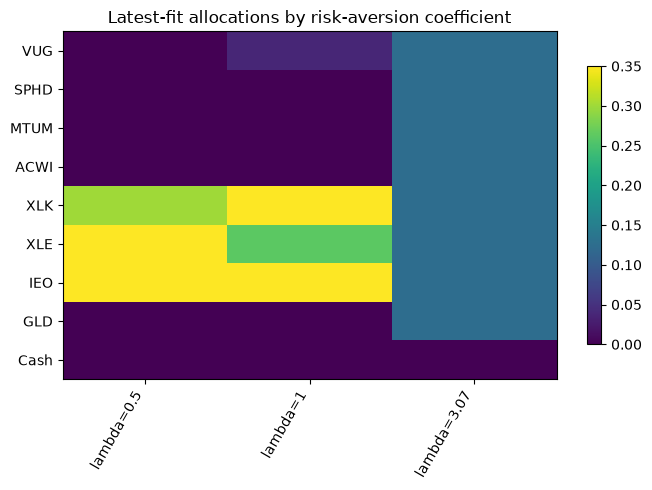

In [20]:
return_vector_weights = pd.DataFrame({
    label: mean_variance_weights(return_comparison[label], result["covariance"], 3.07, MAX_WEIGHT)
    for label in ["Historical excess", "Equilibrium prior", "BL posterior"]
})
return_vector_weights["Equal prior reference"] = 1 / len(ASSETS)
return_vector_weights["BL predictive-covariance sensitivity"] = mean_variance_weights(
    bl["posterior"], bl["predictive_covariance"], 3.07, MAX_WEIGHT)
return_vector_weights.loc["Cash"] = 1 - return_vector_weights.sum()
aversion_weights = pd.DataFrame({f"lambda={level:g}": mean_variance_weights(
    bl["posterior"], result["covariance"], level, MAX_WEIGHT) for level in RISK_AVERSIONS})
aversion_weights.loc["Cash"] = 1 - aversion_weights.sum()
aversion_metrics = []
for label in aversion_weights:
    w = aversion_weights.loc[ASSETS, label].to_numpy()
    aversion_metrics.append({"Scenario": label, "Expected annual excess": w @ bl["posterior"],
                             "Annual volatility": np.sqrt(w @ result["covariance"].to_numpy() @ w),
                             "Cash": aversion_weights.loc["Cash", label]})
aversion_metrics = pd.DataFrame(aversion_metrics).set_index("Scenario")
display(return_vector_weights.style.format("{:.1%}"))
display(aversion_weights.style.format("{:.1%}"))
display(aversion_metrics.style.format("{:.2%}"))
diagnostic_tables.update(return_vector_allocations=return_vector_weights,
                         risk_aversion_weights=aversion_weights, risk_aversion_metrics=aversion_metrics)
show_heatmap(aversion_weights, "Latest-fit allocations by risk-aversion coefficient", "risk_aversion_weights")

## 6. Latest portfolio targets

The table includes risky assets and cash. Long-only methods sum to 100%; fractional Kelly deliberately retains cash. BAB may contain negative asset weights and an offsetting cash position because it is a beta-neutral long/short construction. The full target history is exported for audit.


In [21]:
print(provenance["label"])
display(result["weights"].style.format("{:.1%}"))
print("Budget sums:", result["weights"].sum().round(8).to_dict())
print("Latest BAB diagnostics:")
display(result["bab_diagnostics"].style.format({"Beta": "{:.3f}", "Weight": "{:.2%}"}))
print("BAB estimated beta:", round(result["bab_diagnostics"].attrs["portfolio_beta"], 10))
print("BAB gross exposure:", round(result["bab_diagnostics"].attrs["gross_exposure"], 4))


YAHOO FINANCE - adjusted historical prices, downloaded now


,Equal weight,Minimum variance,BL maximum Sharpe,Minimum tracking error,Higher-moment utility,Fractional Kelly,BAB beta-neutral
VUG,12.5%,0.0%,12.5%,35.0%,30.0%,6.2%,-18.9%
SPHD,12.5%,32.6%,12.5%,22.2%,0.0%,0.0%,31.1%
MTUM,12.5%,0.0%,12.5%,5.3%,0.0%,0.0%,-18.9%
ACWI,12.5%,32.4%,12.5%,28.6%,0.0%,0.0%,31.1%
XLK,12.5%,0.0%,12.5%,7.4%,35.0%,17.5%,-18.9%
XLE,12.5%,0.0%,12.5%,1.5%,0.0%,0.0%,31.1%
IEO,12.5%,0.0%,12.5%,0.0%,0.0%,17.5%,-18.9%
GLD,12.5%,35.0%,12.5%,0.0%,35.0%,8.8%,31.1%
Cash,0.0%,0.0%,0.0%,0.0%,0.0%,50.0%,51.1%


Budget sums: {'Equal weight': 1.0, 'Minimum variance': 1.0, 'BL maximum Sharpe': 1.0, 'Minimum tracking error': 1.0, 'Higher-moment utility': 1.0, 'Fractional Kelly': 1.0, 'BAB beta-neutral': 1.0}
Latest BAB diagnostics:


,Beta,Weight,Leg
Ticker,,,
GLD,0.142,31.11%,Low-beta long
SPHD,0.745,31.11%,Low-beta long
XLE,0.930,31.11%,Low-beta long
ACWI,0.931,31.11%,Low-beta long
IEO,1.030,-18.89%,High-beta short
MTUM,1.059,-18.89%,High-beta short
VUG,1.158,-18.89%,High-beta short
XLK,1.280,-18.89%,High-beta short


BAB estimated beta: -0.0
BAB gross exposure: 2.0


### Calculation: Third/fourth-order moments and portfolio contractions

In [22]:
def higher_moment_diagnostics(returns, weights):
    """Population central tensors contracted into the actual portfolio moments.

    Raw asset moments must be contracted before standardizing by portfolio
    volatility. Contracting standardized asset co-moments with raw weights does
    not produce portfolio skewness/kurtosis. No small-sample correction is used.
    """
    data = _numeric_frame(returns, 'returns')
    w = pd.Series(weights).reindex(data.columns).to_numpy(dtype=float)
    if not np.isfinite(w).all():
        raise ValueError('Weights must cover each asset.')
    x = data.to_numpy() - data.mean().to_numpy()
    n = len(x)
    second = x.T @ x / n
    third = np.einsum('ti,tj,tk->ijk', x, x, x, optimize=True) / n
    fourth = np.einsum('ti,tj,tk,tl->ijkl', x, x, x, x, optimize=True) / n
    variance = float(w @ second @ w)
    if variance <= 0 or (np.diag(second) <= 0).any():
        raise ValueError('Higher moments require positive portfolio and asset variances.')
    skewness = float(np.einsum('i,j,k,ijk', w, w, w, third) / variance ** 1.5)
    kurtosis = float(np.einsum('i,j,k,l,ijkl', w, w, w, w, fourth) / variance ** 2)
    z = x / np.sqrt(np.diag(second))
    pair_skew = (z ** 2).T @ z / n
    pair_kurt = (z ** 2).T @ (z ** 2) / n
    portfolio = x @ w
    checks = pd.DataFrame({
        'Tensor contraction': [variance, skewness, kurtosis - 3],
        'Direct portfolio sample': [np.mean(portfolio ** 2),
                                    np.mean(portfolio ** 3) / variance ** 1.5,
                                    np.mean(portfolio ** 4) / variance ** 2 - 3]},
        index=['Daily variance', 'Skewness', 'Excess kurtosis'])
    checks['Absolute difference'] = (checks.iloc[:, 0] - checks.iloc[:, 1]).abs()
    return {'third': third, 'fourth': fourth, 'checks': checks,
            'pair_coskewness': pd.DataFrame(pair_skew, index=data.columns, columns=data.columns),
            'pair_cokurtosis': pd.DataFrame(pair_kurt, index=data.columns, columns=data.columns)}

### Co-skewness, co-kurtosis and portfolio-moment verification

The original third/fourth-order tensors are restored using **raw daily central
moments**. Contracting them with the higher-moment optimizer's own weights and then
standardizing must reproduce skewness and excess kurtosis of that portfolio's
sample return series. Population moments are used consistently for this identity;
the optimizer's finite-sample corrected statistics have a different convention.

The displayed pairwise slices are `E[z_i^2 z_j]` and `E[z_i^2 z_j^2]`, where z is an
asset's standardized daily return. The latter is raw co-kurtosis; subtracting 3
from every off-diagonal entry would not define a valid general excess co-moment.

,Tensor contraction,Direct portfolio sample,Absolute difference
Daily variance,0.000144,0.000144,2.710505e-20
Skewness,-0.072308,-0.072308,4.163336e-17
Excess kurtosis,7.704868,7.704868,1.953993e-14


Tensor shapes: (8, 8, 8) (8, 8, 8, 8)


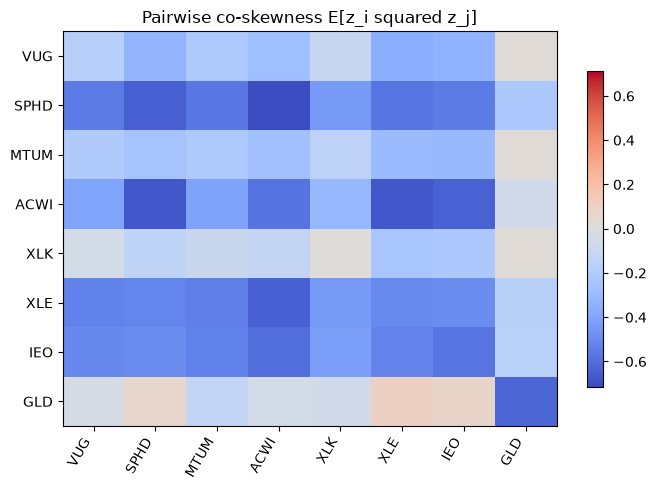

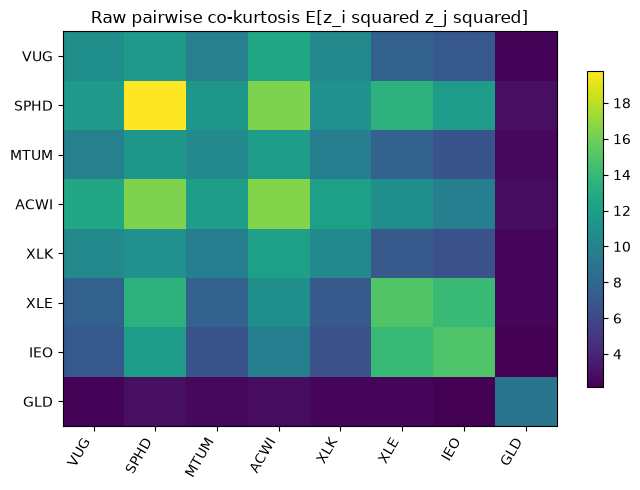

In [23]:
moment_diagnostics = higher_moment_diagnostics(last_train[ASSETS], result["weights"].loc[ASSETS, "Higher-moment utility"])
display(moment_diagnostics["checks"])
assert moment_diagnostics["checks"]["Absolute difference"].max() < 1e-8
print("Tensor shapes:", moment_diagnostics["third"].shape, moment_diagnostics["fourth"].shape)
diagnostic_tables.update(higher_moment_checks=moment_diagnostics["checks"],
                         pair_coskewness=moment_diagnostics["pair_coskewness"],
                         pair_cokurtosis=moment_diagnostics["pair_cokurtosis"])
show_heatmap(moment_diagnostics["pair_coskewness"], "Pairwise co-skewness E[z_i squared z_j]", "pair_coskewness", centered=True)
show_heatmap(moment_diagnostics["pair_cokurtosis"], "Raw pairwise co-kurtosis E[z_i squared z_j squared]", "pair_cokurtosis")

## 7. Model, implementation and walk-forward results

The model table describes the final pre-trade estimates. The implementation table aggregates one-way turnover and modeled costs. Historical statistics use only later walk-forward returns and include transaction and short-borrow costs for portfolio strategies; SPY is an uncosted reference.

Only numerical parameter fitting is chronological. The universe was chosen in August 2024; original views are commented out unless explicitly restored, so these results are not a point-in-time out-of-sample strategy test. The views are fixed scenarios, parameters were not selected through nested validation, and the cost model does not include market impact, taxes or locate constraints.


In [24]:
print("LATEST MODEL ESTIMATES —", provenance["label"])
display(result["model"].style.format({"Expected annual return": "{:.2%}",
                                      "Annual volatility": "{:.2%}", "Expected Sharpe": "{:.2f}"}))
print("IMPLEMENTATION —", TRANSACTION_COST_BPS, "bps transaction cost;",
      ANNUAL_SHORT_BORROW_BPS, "bps annual short borrow")
display(result["trading"].style.format({"One-way turnover": "{:.2f}",
                                        "Estimated cost": "{:.2%}",
                                        "Estimated short-borrow cost": "{:.2%}",
                                        "Estimated total implementation cost": "{:.2%}",
                                        "Annualized one-way turnover": "{:.2f}",
                                        "Cost assumption (bps)": "{:.0f}"}))
print("NET WALK-FORWARD HISTORY —", provenance["label"])
display(result["historical"].style.format({"Annual mean": "{:.2%}", "CAGR": "{:.2%}",
                                           "Annual volatility": "{:.2%}", "Sharpe": "{:.2f}",
                                           "Max drawdown": "{:.2%}"}))


LATEST MODEL ESTIMATES — YAHOO FINANCE - adjusted historical prices, downloaded now


,Expected annual return,Annual volatility,Expected Sharpe
Equal weight,15.11%,19.86%,0.61
Minimum variance,10.65%,14.51%,0.53
BL maximum Sharpe,15.11%,19.86%,0.61
Minimum tracking error,14.43%,20.22%,0.57
Higher-moment utility,12.63%,19.05%,0.51
Fractional Kelly,9.73%,11.24%,0.60
BAB beta-neutral,4.58%,12.05%,0.13


IMPLEMENTATION — 10 bps transaction cost; 100 bps annual short borrow


,One-way turnover,Estimated cost,Estimated short-borrow cost,Estimated total implementation cost,Annualized one-way turnover,Cost assumption (bps)
Portfolio,,,,,,
Equal weight,2.00,0.20%,0.00%,0.20%,0.42,10
Minimum variance,1.82,0.18%,0.00%,0.18%,0.38,10
BL maximum Sharpe,2.00,0.20%,0.00%,0.20%,0.42,10
Minimum tracking error,1.62,0.16%,0.00%,0.16%,0.34,10
Higher-moment utility,3.10,0.31%,0.00%,0.31%,0.65,10
Fractional Kelly,3.03,0.30%,0.00%,0.30%,0.64,10
BAB beta-neutral,5.50,0.55%,3.68%,4.23%,1.16,10


NET WALK-FORWARD HISTORY — YAHOO FINANCE - adjusted historical prices, downloaded now


,Annual mean,CAGR,Annual volatility,Sharpe,Sortino,Max drawdown
Equal weight,17.25%,17.35%,15.76%,0.91,1.285642,-16.95%
Minimum variance,12.00%,11.86%,12.59%,0.72,1.020211,-18.83%
BL maximum Sharpe,17.25%,17.35%,15.76%,0.91,1.285642,-16.95%
Minimum tracking error,12.56%,11.76%,16.99%,0.57,0.814223,-25.87%
Higher-moment utility,17.40%,17.08%,18.02%,0.80,1.144307,-22.46%
Fractional Kelly,8.52%,8.28%,10.56%,0.53,0.724555,-11.27%
BAB beta-neutral,-0.82%,-1.40%,10.94%,-0.34,-0.483399,-28.71%
SPY,13.12%,12.33%,17.30%,0.59,0.847388,-24.50%


### Realized BAB exposure and active performance

Zero estimated beta at rebalance does not guarantee zero realized rolling beta.
The net strategy's rolling alpha/beta uses prior observations of the resulting
return stream and the window selected in initial training. Tracking error is the
annualized standard deviation of daily strategy minus SPY returns; information
ratio divides annual active mean by that tracking error. SPY's self-comparison is
undefined for information ratio, so its zero denominator is displayed as missing.

,Annual mean,CAGR,Annual volatility,Sharpe,Sortino,Max drawdown,Tracking error,Information ratio
Equal weight,0.1725,0.1735,0.1576,0.9070,1.2856,-0.1695,0.0787,0.5248
Minimum variance,0.1200,0.1186,0.1259,0.7186,1.0202,-0.1883,0.1103,-0.1009
BL maximum Sharpe,0.1725,0.1735,0.1576,0.9070,1.2856,-0.1695,0.0787,0.5248
Minimum tracking error,0.1256,0.1176,0.1699,0.5656,0.8142,-0.2587,0.0219,-0.2529
Higher-moment utility,0.1740,0.1708,0.1802,0.8014,1.1443,-0.2246,0.1012,0.4232
Fractional Kelly,0.0852,0.0828,0.1056,0.5266,0.7246,-0.1127,0.1099,-0.4184
BAB beta-neutral,-0.0082,-0.0140,0.1094,-0.3449,-0.4834,-0.2871,0.2115,-0.6588
SPY,0.1312,0.1233,0.1730,0.5875,0.8474,-0.2450,0.0000,NaN


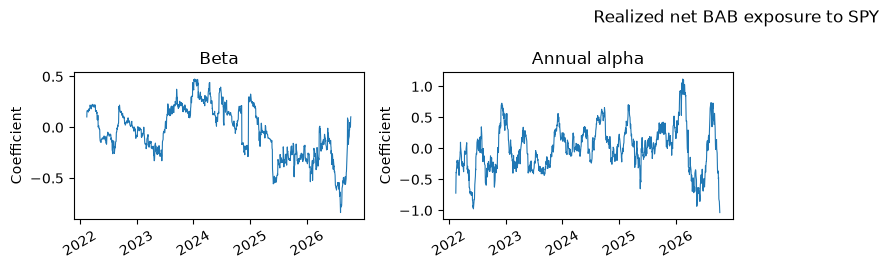

In [25]:
active_metrics = performance_table(result["portfolio_returns"], ANNUAL_RISK_FREE_RATE,
                                   benchmark=result["portfolio_returns"][BENCHMARK])
bab_rolling = rolling_market_model(result["portfolio_returns"][["BAB beta-neutral"]],
                                    result["portfolio_returns"][BENCHMARK], best_window, ANNUAL_RISK_FREE_RATE)
bab_exposure = pd.concat([bab_rolling["beta"].iloc[:, 0].rename("Beta"),
                          bab_rolling["annual_alpha"].iloc[:, 0].rename("Annual alpha")], axis=1)
display(active_metrics.round(4))
diagnostic_tables.update(active_performance=active_metrics, bab_rolling_exposure=bab_exposure)
show_panels(bab_exposure, "Realized net BAB exposure to SPY", "bab_rolling_exposure", "Coefficient")

### Calculation: Evaluate a dated target history using the holdings ledger

In [26]:
def evaluate_targets(asset_returns, targets, annual_rf=.03, transaction_cost_bps=10,
                     annual_short_borrow_bps=100):
    """Evaluate precomputed dated targets with the same ledger as the main run.

    Caller is responsible for fitting targets before their effective dates.
    A target table includes asset columns and Cash and must start on day one.
    """
    returns = _numeric_frame(asset_returns, 'asset_returns', minimum_rows=2)
    targets = _numeric_frame(targets, 'targets', minimum_rows=1)
    names = list(returns.columns)
    if (list(targets.columns) != names + ['Cash'] or targets.index[0] != returns.index[0]
            or not targets.index.isin(returns.index).all()
            or not np.allclose(targets.sum(axis=1), 1)):
        raise ValueError('Targets must cover the initial date, assets and cash budget.')
    if (not np.isfinite([annual_rf, transaction_cost_bps, annual_short_borrow_bps]).all()
            or annual_rf <= -1 or min(transaction_cost_bps, annual_short_borrow_bps) < 0):
        raise ValueError('Invalid financing/cost assumptions.')
    rf = (1 + annual_rf) ** (1 / 252) - 1
    borrow = annual_short_borrow_bps / 10000 / 252
    w, cash = np.zeros(len(names)), 1.0
    result, trades = [], []
    for date, row in returns.iterrows():
        cost = 0.0
        if date in targets.index:
            target = targets.loc[date, names].to_numpy()
            target_cash = float(targets.loc[date, 'Cash'])
            turnover = (np.abs(target - w).sum() + abs(target_cash - cash)) / 2
            cost = turnover * transaction_cost_bps / 10000
            trades.append({'Date': date, 'One-way turnover': turnover, 'Estimated cost': cost})
            w, cash = target, target_cash
        net, w, cash, _ = portfolio_step(w, cash, row.to_numpy(), rf, borrow, cost)
        result.append(net)
    return pd.Series(result, index=returns.index), pd.DataFrame(trades).set_index('Date')

### Fractional Kelly: 0.50, 0.66 and 1.00

Each rebalance solves a long-only, unlevered **full-Kelly log-growth problem with
cash available**, using only the prior window. Fractions scale that same full
solution, so 50% Kelly can invest less than 50% of capital when full Kelly retains
cash. The asset cap applies before scaling. This replaces the previous forced
risky-sleeve implementation and the original inverse-covariance/gross-normalization
illustration. Wealth compounds simple returns at the correct timestamp.

Every comparison below includes monthly turnover, trading costs and cash interest
using the main portfolio ledger. It remains subject to the retrospective universe
selection caveat and is not an unconstrained leveraged Kelly solution.

,Annual mean,CAGR,Annual volatility,Sharpe,Sortino,Max drawdown
Kelly 0.50,0.0852,0.0828,0.1056,0.5266,0.7246,-0.1127
Kelly 0.66,0.1036,0.0983,0.1397,0.5297,0.7298,-0.1481
Kelly 1.00,0.1437,0.1286,0.2128,0.5363,0.7412,-0.2237
SPY,0.1312,0.1233,0.1730,0.5875,0.8474,-0.2450


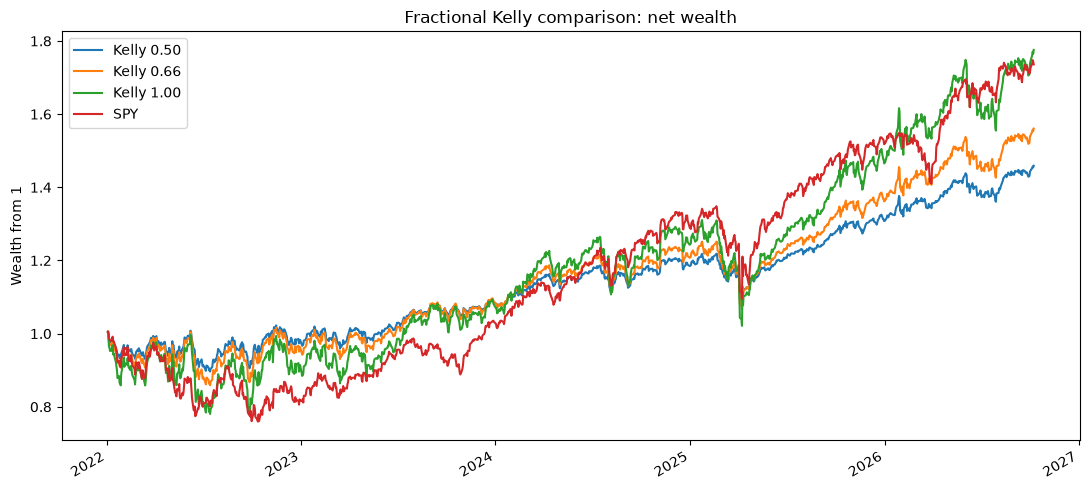

In [27]:
kelly_dates = result["weight_history"].index.get_level_values("Date").unique()
kelly_targets = {fraction: [] for fraction in KELLY_COMPARISON_FRACTIONS}
for date in kelly_dates:
    train = result["returns"].loc[result["returns"].index < date, ASSETS]
    full = fractional_kelly_weights(train, ANNUAL_RISK_FREE_RATE, fraction=1.0, cap=MAX_WEIGHT)
    for fraction in KELLY_COMPARISON_FRACTIONS:
        target = full * fraction
        kelly_targets[fraction].append({"Date": date, **target.to_dict(), "Cash": 1 - target.sum()})
kelly_returns = pd.DataFrame(index=result["portfolio_returns"].index)
for fraction, records in kelly_targets.items():
    targets = pd.DataFrame(records).set_index("Date")[ASSETS + ["Cash"]]
    series, turnover = evaluate_targets(result["returns"].loc[kelly_returns.index, ASSETS], targets,
                                        ANNUAL_RISK_FREE_RATE, TRANSACTION_COST_BPS, ANNUAL_SHORT_BORROW_BPS)
    label = f"Kelly {fraction:.2f}"
    kelly_returns[label] = series
    diagnostic_tables[f"kelly_{fraction:.2f}_targets"] = targets
    diagnostic_tables[f"kelly_{fraction:.2f}_turnover"] = turnover
if KELLY_FRACTION in KELLY_COMPARISON_FRACTIONS:
    assert np.allclose(kelly_returns[f"Kelly {KELLY_FRACTION:.2f}"], result["portfolio_returns"]["Fractional Kelly"])
kelly_returns[BENCHMARK] = result["portfolio_returns"][BENCHMARK]
kelly_metrics = performance_table(kelly_returns, ANNUAL_RISK_FREE_RATE)
display(kelly_metrics.round(4))
diagnostic_tables.update(kelly_comparison_returns=kelly_returns, kelly_comparison_metrics=kelly_metrics)
fig, ax = plt.subplots(figsize=(11, 5))
(1 + kelly_returns).cumprod().plot(ax=ax)
ax.set(title="Fractional Kelly comparison: net wealth", ylabel="Wealth from 1")
fig.tight_layout()
diagnostic_figures["kelly_comparison"] = fig
plt.show()
plt.close(fig)

### Calculation: Monthly compounding and explicit factor-unit conversion

In [28]:
def monthly_compound(daily_returns, trim_boundary_months=True):
    """Compound daily returns; conservatively exclude both boundary months.

    A return-only series cannot prove complete first/last month coverage. Trimming
    prevents partial periods being regressed against full-month factor returns.
    Set False only when complete coverage has been independently established.
    """
    daily = _numeric_frame(daily_returns, 'daily_returns', minimum_rows=40)
    if not isinstance(daily.index, pd.DatetimeIndex):
        raise ValueError('daily_returns must use a DatetimeIndex.')
    periods = daily.index.to_period('M')
    monthly = (1 + daily).groupby(periods).prod() - 1
    if trim_boundary_months:
        monthly = monthly.iloc[1:-1]
    monthly.index = monthly.index.to_timestamp('M')
    return monthly


def load_fama_french_csv(path, unit='percent'):
    """Load a cleaned monthly Fama-French five-factor CSV with explicit units."""
    if unit not in {'percent', 'decimal'}:
        raise ValueError('unit must be "percent" or "decimal".')
    frame = pd.read_csv(Path(path))
    date_column = frame.columns[0]
    dates = frame[date_column].astype(str).str.strip()
    valid = dates.str.fullmatch(r'\d{6}')
    if not valid.all():
        raise ValueError('Cleaned factor file must contain only YYYYMM monthly rows.')
    frame = frame.loc[valid].copy()
    frame.index = pd.to_datetime(dates.loc[valid], format='%Y%m') + pd.offsets.MonthEnd(0)
    required = FACTOR_COLUMNS + ['RF']
    missing = set(required) - set(frame.columns)
    if missing:
        raise ValueError(f'Factor file is missing columns: {sorted(missing)}')
    frame = _numeric_frame(frame[required], 'factor file')
    if unit == 'percent':
        frame /= 100
    if frame.abs().max().max() >= 1:
        raise ValueError('Factor values are implausible decimal returns; check the unit setting.')
    frame.attrs['source_unit'] = unit
    frame.attrs['stored_unit'] = 'decimal'
    return frame

### Calculation: Five-factor time-series regression

In [29]:
def factor_regression(monthly_asset_returns, monthly_factors):
    """OLS excess-return regressions on the Fama-French five factors.

    Both inputs must already be decimals. The output reports annualized alpha,
    factor loadings, coefficient t-statistics, R-squared and observation count.
    """
    assets = _numeric_frame(monthly_asset_returns, 'monthly_asset_returns')
    factors = _numeric_frame(monthly_factors, 'monthly_factors')
    required = FACTOR_COLUMNS + ['RF']
    if not set(required).issubset(factors.columns):
        raise ValueError(f'monthly_factors requires {required}.')
    joined = assets.join(factors[required], how='inner').dropna()
    if len(joined) < 24:
        raise ValueError('Too few aligned months for factor regression; at least 24 required.')
    x = np.column_stack([np.ones(len(joined)), joined[FACTOR_COLUMNS].to_numpy()])
    if np.linalg.matrix_rank(x) < x.shape[1]:
        raise ValueError('Factor design matrix is rank deficient.')
    xtx_inverse = np.linalg.pinv(x.T @ x)
    rows = []
    for asset in assets.columns:
        y = (joined[asset] - joined['RF']).to_numpy()
        coefficients = np.linalg.lstsq(x, y, rcond=None)[0]
        residuals = y - x @ coefficients
        dof = len(y) - x.shape[1]
        residual_variance = float(residuals @ residuals / dof)
        standard_errors = np.sqrt(np.diag(xtx_inverse) * residual_variance)
        t_stats = np.divide(coefficients, standard_errors,
                            out=np.full_like(coefficients, np.nan), where=standard_errors > 0)
        total = float(((y - y.mean()) ** 2).sum())
        r_squared = 1 - float(residuals @ residuals) / total if total > 0 else np.nan
        row = {'Portfolio': asset, 'Annual alpha': coefficients[0] * 12,
               'Alpha t-stat': t_stats[0], 'R-squared': r_squared,
               'Observations': len(y),
               'First month': str(joined.index.min().date()),
               'Last month': str(joined.index.max().date())}
        for number, factor in enumerate(FACTOR_COLUMNS, start=1):
            row[f'{factor} loading'] = coefficients[number]
            row[f'{factor} t-stat'] = t_stats[number]
        rows.append(row)
    return pd.DataFrame(rows).set_index('Portfolio')

## 8. Fama–French five-factor attribution

**ORIGINAL 2024 SUBMISSION:** the included factor file ends in June 2024. Its
configuration line is commented out and it is not used automatically with 2026 prices.
Set `FACTOR_FILE` to an updated cleaned monthly CSV and declare `FACTOR_UNIT` to
enable the analysis. Until then, this section prints an explicit inactive status;
no factor values are fabricated or carried forward. Loaded coverage is printed.

Daily decimal returns are compounded to months; boundary months are omitted.
Only dates overlapping the selected factors are fitted. Time-series OLS reports
loadings, alpha (monthly intercept times 12), IID t-statistics, dates and counts.
This is attribution, not Fama–MacBeth estimation or automatic weight adjustment.


In [30]:
factor_path = Path(FACTOR_FILE) if FACTOR_FILE else None
factors = None
factor_results = universe_factor_results = None
if DATA_MODE == "synthetic":
    print("Real-factor attribution omitted for synthetic prices.")
elif factor_path is None:
    print("Factor analysis inactive: supply an updated FACTOR_FILE. The original June-2024 file is commented out.")
elif factor_path.exists():
    factors = load_fama_french_csv(factor_path, unit=FACTOR_UNIT)
    provenance["factor_file_sha256"] = file_sha256(factor_path)
    provenance["factor_unit"] = FACTOR_UNIT
    print("Selected factor coverage:", factors.index.min().date(), "to", factors.index.max().date())
    monthly_portfolios = monthly_compound(result["portfolio_returns"])
    factor_results = factor_regression(monthly_portfolios, factors)
    print("NET STRATEGIES AND SPY: monthly time-series attribution")
    display(factor_results)
    if universe_prices is not None:
        universe_monthly = monthly_compound(universe_daily)
        universe_factor_results = factor_regression(universe_monthly, factors)
        print(f"LOADED UNIVERSE ({len(universe_prices.columns)} ETFs): monthly time-series attribution")
        display(universe_factor_results)
else:
    raise FileNotFoundError(f"Factor attribution requires the declared file: {factor_path}")


Factor analysis inactive: supply an updated FACTOR_FILE. The original June-2024 file is commented out.


### Calculation: Full-model fitted excess returns

In [31]:
def factor_fit_diagnostics(monthly_returns, factors):
    """Fitted excess returns use every factor, not a partial market-only line."""
    coefficients = factor_regression(monthly_returns, factors)
    dates = monthly_returns.index.intersection(factors.index)
    actual = monthly_returns.loc[dates].sub(factors.loc[dates, 'RF'], axis=0)
    fitted = pd.DataFrame(index=dates)
    for name in monthly_returns:
        beta = coefficients.loc[name, [f'{f} loading' for f in FACTOR_COLUMNS]].to_numpy(dtype=float)
        fitted[name] = coefficients.loc[name, 'Annual alpha'] / 12 + factors.loc[dates, FACTOR_COLUMNS].to_numpy() @ beta
    return coefficients, actual, fitted

### Factor loadings and fitted-return diagnostics

The original scatter plots are restored as observed versus fitted **excess returns
using all five factors**. A market-only line drawn from a multivariate model would
omit the other four contributions. These are in-sample attribution diagnostics;
their fit is not evidence of forecasting skill. Loadings are dimensionless and
use decimal ETF and factor returns. Synthetic mode does not pair simulated returns
with real factors.

In [32]:
factor_loadings = None
if factors is not None:
    allocation_monthly = monthly_compound(universe_daily[ASSETS])
    asset_factor_results, actual_factor_excess, fitted_factor_excess = factor_fit_diagnostics(allocation_monthly, factors)
    factor_loadings = asset_factor_results[[f"{f} loading" for f in FACTOR_COLUMNS]].copy()
    factor_loadings.columns = FACTOR_COLUMNS
    display(factor_loadings.round(4))
    diagnostic_tables.update(allocation_factor_loadings=factor_loadings,
                             factor_actual_excess=actual_factor_excess, factor_fitted_excess=fitted_factor_excess)
    show_heatmap(factor_loadings, "Five-factor ETF loadings: full overlapping sample", "factor_loadings", centered=True)
    fig, axes = plt.subplots(4, 2, figsize=(11, 13))
    for ax, name in zip(axes.flat, ASSETS):
        x, y = fitted_factor_excess[name], actual_factor_excess[name]
        ax.scatter(x, y, s=12, alpha=.6)
        low, high = min(x.min(), y.min()), max(x.max(), y.max())
        ax.plot([low, high], [low, high], color="red", linewidth=.8)
        ax.set(title=name, xlabel="Fitted excess return (all five factors)", ylabel="Observed excess return")
    fig.suptitle("In-sample factor attribution diagnostics")
    fig.tight_layout()
    diagnostic_figures["factor_fit"] = fig
    plt.show()
    plt.close(fig)
else:
    print("Factor fit plots inactive: no real factor dataset selected.")

Factor fit plots inactive: no real factor dataset selected.


### Calculation: Allocation and net-wealth chart construction

In [33]:
def charts(result, label):
    import matplotlib.pyplot as plt
    weights_figure, ax = plt.subplots(figsize=(11, 5))
    (result['weights'] * 100).plot.bar(ax=ax)
    ax.set(title=f'{label}\nLatest walk-forward target weights', ylabel='Allocation (%)', xlabel='Asset label')
    ax.legend(fontsize=8)
    weights_figure.tight_layout()
    growth_figure, ax = plt.subplots(figsize=(11, 5))
    rets = result['portfolio_returns']
    growth = (1 + rets).cumprod()
    initial = pd.DataFrame(1.0, index=[rets.index[0] - pd.Timedelta(days=1)], columns=rets.columns)
    growth = pd.concat([initial, growth])
    growth.plot(ax=ax)
    ax.set(title=f'{label}\nWalk-forward growth - portfolio returns are after stated costs',
           ylabel='Growth of 1 unit', xlabel='Date')
    ax.legend(fontsize=8)
    growth_figure.tight_layout()
    return weights_figure, growth_figure

## 9. Portfolio charts

The allocation chart includes cash and signed BAB weights. The growth chart covers only the later walk-forward period. Portfolio series are net of the stated modeled costs; SPY is an uncosted reference.


C:\Users\user\pythonlab\portfolio-construction-repo\.setup-tmp\ipykernel_44412\37154178.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  initial = pd.DataFrame(1.0, index=[rets.index[0] - pd.Timedelta(days=1)], columns=rets.columns)


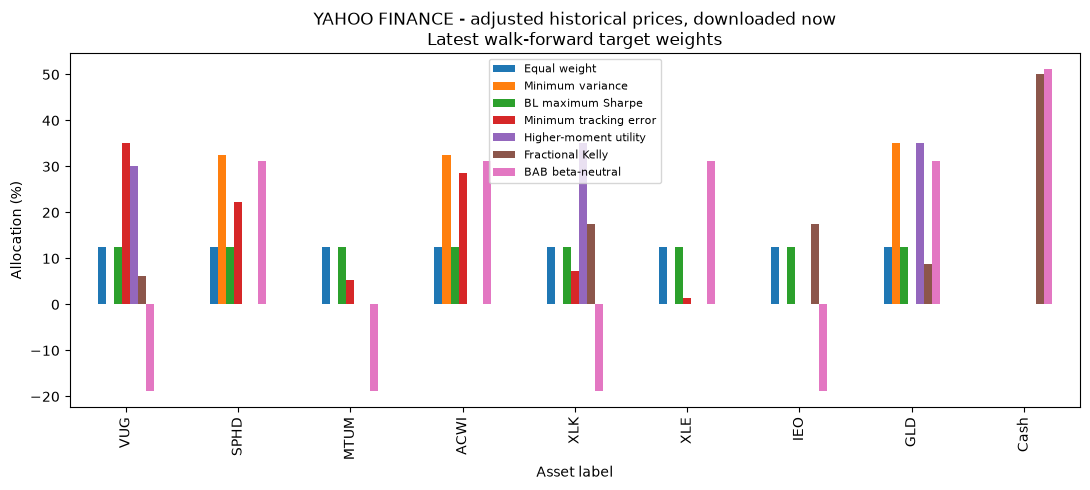

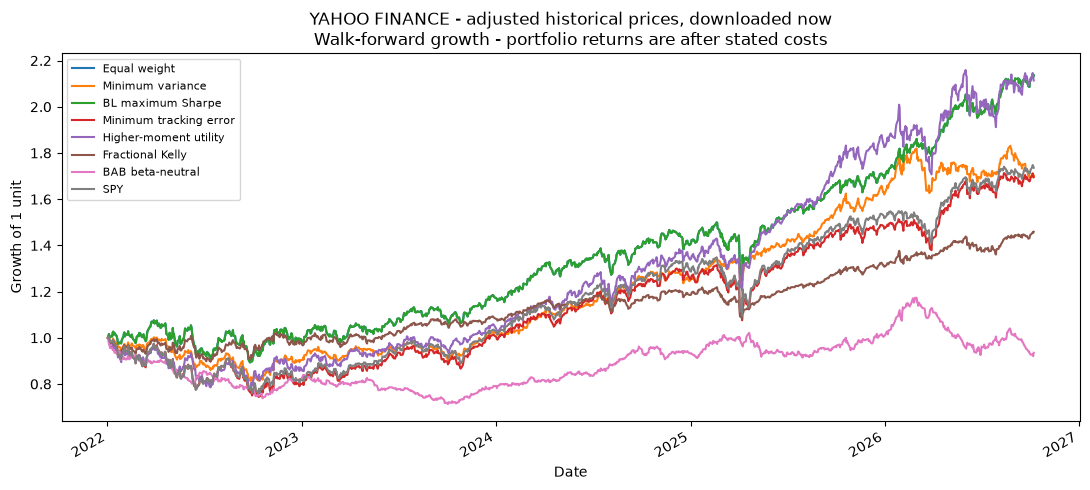

In [34]:
weight_chart, growth_chart = charts(result, provenance["label"])
plt.show()

## Research interpretation and next work

This implementation makes the portfolio methods and evaluation contract explicit and testable. It does not treat the best historical Sharpe ratio as proof of superiority. Useful next work includes multiple non-overlapping evaluation periods, parameter stability maps, block-bootstrap uncertainty, alternative view-generation processes, point-in-time factor vintages and richer execution-cost models.

### References

- Black, F. and Litterman, R. (1992), *Global Portfolio Optimization*, Financial Analysts Journal, 48(5), 28–43.
- Fama, E. F. and French, K. R. (2015), *A Five-Factor Asset Pricing Model*, Journal of Financial Economics, 116(1), 1–22.
- Frazzini, A. and Pedersen, L. H. (2014), *Betting Against Beta*, Journal of Financial Economics, 111(1), 1–25.
- Kelly, J. L. (1956), *A New Interpretation of Information Rate*, Bell System Technical Journal, 35(4), 917–926.
- `AMENDMENTS.md` documents corrections from the 2024 implementation.

This repository is quantitative research code, not personalized investment advice or evidence of future returns.


## Supplementary experiments and market context

The following source analyses help inspect assumptions but are not inputs to the
seven-strategy allocation process. They are kept executable here, after the research
interpretation, with their data dates and limitations stated. They do not modify
the strategy return streams above.

### Calculation: Proportional allocation with repeated cap enforcement

In [35]:
def capped_proportional_weights(scores, cap=0.35):
    """Allocate proportionally, repeatedly fixing saturated assets at their cap."""
    scores = pd.Series(scores, dtype=float).copy()
    if (scores.index.has_duplicates or not np.isfinite(scores).all()
            or (scores < 0).any() or scores.sum() <= 0
            or not 1 / len(scores) <= cap <= 1):
        raise ValueError('Scores must be nonnegative with a feasible cap and positive total.')
    weights = pd.Series(0.0, index=scores.index)
    free = list(scores.index)
    remaining = 1.0
    while free:
        values = scores.loc[free]
        proposal = remaining * (values / values.sum() if values.sum() > 0 else pd.Series(1 / len(free), index=free))
        saturated = proposal.index[proposal > cap + 1e-12]
        if len(saturated) == 0:
            weights.loc[free] = proposal
            break
        weights.loc[saturated] = cap
        remaining = 1 - weights.sum()
        free = [name for name in free if name not in saturated]
    return weights

### A. Submission AUM snapshot and capped allocation illustration

The cache repeats one AUM value per ETF across its history. It does not contain a
dated AUM time series. ETF AUM also is not the market capitalization of a disjoint
set of underlying investments. These snapshot weights therefore remain an
illustration, not historical equilibrium weights. The 20-candidate allocation uses
a 10% cap; the selected eight use `MAX_WEIGHT` because an eight-asset 10% cap cannot
sum to one. Iterative proportional redistribution enforces every cap simultaneously.

**Original input status:** these unchanged submission inputs are inactive by default. `RUN_ORIGINAL_CONTEXT=True` explicitly re-enables the historical illustration; this does not update its vintage.

In [36]:
# ORIGINAL 2024 SUBMISSION AUM — explicit opt-in only.
if RUN_ORIGINAL_CONTEXT and DATA_MODE != "synthetic":
    aum_raw = pd.read_csv(Path("data") / "efts_dataset.csv")
    aum_counts = aum_raw.groupby("ETF")["Market Cap"].nunique(dropna=False)
    if not (aum_counts == 1).all():
        raise ValueError("Expected one repeated AUM snapshot per ETF; inspect the source.")
    aum = pd.to_numeric(aum_raw.groupby("ETF")["Market Cap"].first(), errors="raise").drop(index=BENCHMARK)
    if not np.isfinite(aum).all() or (aum <= 0).any():
        raise ValueError("Snapshot AUM must be positive and finite.")
    aum_table = pd.DataFrame({"AUM snapshot (source units)": aum, "Proportional weight": aum / aum.sum(),
                              "Capped candidate weight": capped_proportional_weights(aum, .10)})
    selected_aum = pd.DataFrame({"Proportional snapshot": aum.loc[ASSETS] / aum.loc[ASSETS].sum(),
                                 "Capped snapshot": capped_proportional_weights(aum.loc[ASSETS], MAX_WEIGHT),
                                 "Equal prior used by workflow": 1 / len(ASSETS)})
    display(aum_table)
    display(selected_aum.style.format("{:.1%}"))
    diagnostic_tables.update(aum_snapshot_illustration=aum_table, selected_aum_illustration=selected_aum)
else:
    print("Original 2024 AUM snapshot inactive: RUN_ORIGINAL_CONTEXT=False (or synthetic mode).")

Original 2024 AUM snapshot inactive: RUN_ORIGINAL_CONTEXT=False (or synthetic mode).


### Calculation: Factor-threshold sensitivity rule

In [37]:
def factor_tilt(weights, loadings, positive_threshold, negative_threshold, cap=.35):
    """Original +/-10% per-factor heuristic, with repeated cap enforcement."""
    base = pd.Series(weights, dtype=float)
    loadings = pd.DataFrame(loadings).loc[base.index]
    if (not np.isfinite(loadings.to_numpy()).all() or positive_threshold <= 0
            or negative_threshold <= 0):
        raise ValueError('Loadings must be finite and thresholds positive.')
    positive = (loadings >= positive_threshold).sum(axis=1)
    negative = (loadings <= -negative_threshold).sum(axis=1)
    scores = base * 1.1 ** positive * .9 ** negative
    return capped_proportional_weights(scores, cap)

### B. Factor-threshold allocation heuristic

The original rule multiplies an ETF weight by 1.1 for a positive loading and 0.9
for a negative loading exceeding a threshold. A loading's sign alone is not a
forecast of a factor premium. This is a sensitivity experiment, not Fama–MacBeth
estimation or a validated investment rule.

We restore both the original numerical thresholds (+0.010 / -0.008) and an adaptive
absolute-loading mean-plus-standard-deviation threshold. The old thresholds were
chosen using inconsistent units; here they are explicitly **illustrative** on
corrected dimensionless loadings. All five factors contribute; output is capped
and normalized after the multipliers. Fits stop before the last rebalance and
use the available factor vintage. Before/after monthly statistics use 12 periods
per year and the same calibration sample. They are gross in-sample constant-weight
illustrations, not the net walk-forward strategy results.

In [38]:
if factors is not None:
    tilt_monthly = monthly_compound(last_train[ASSETS])
    tilt_fit, tilt_actual, _ = factor_fit_diagnostics(tilt_monthly, factors)
    tilt_loadings = tilt_fit[[f"{f} loading" for f in FACTOR_COLUMNS]].copy()
    tilt_loadings.columns = FACTOR_COLUMNS
    absolute_loadings = tilt_loadings.abs().to_numpy().ravel()
    adaptive_threshold = float(absolute_loadings.mean() + absolute_loadings.std(ddof=0))
    base = pd.Series(1 / len(ASSETS), index=ASSETS)
    tilt_weights = pd.DataFrame({"Equal reference": base,
        "Original numerical thresholds": factor_tilt(base, tilt_loadings, .010, .008, MAX_WEIGHT),
        "Adaptive threshold": factor_tilt(base, tilt_loadings, adaptive_threshold, adaptive_threshold, MAX_WEIGHT)})
    threshold_summary = pd.DataFrame({"Positive threshold": [.010, adaptive_threshold],
                                      "Negative magnitude threshold": [.008, adaptive_threshold]},
                                     index=["Original numerical thresholds", "Adaptive threshold"])
    filtered_loadings = tilt_loadings.where((tilt_loadings >= .010) | (tilt_loadings <= -.008))
    tilt_sample = tilt_monthly.loc[tilt_actual.index]
    tilt_returns = tilt_sample @ tilt_weights
    tilt_metrics = performance_table(tilt_returns, ANNUAL_RISK_FREE_RATE, periods_per_year=12)
    print("Calibration months:", tilt_sample.index.min().date(), "to", tilt_sample.index.max().date())
    display(threshold_summary)
    display(filtered_loadings.round(4))
    display(tilt_weights.style.format("{:.2%}"))
    display(tilt_metrics.round(4))
    diagnostic_tables.update(factor_tilt_thresholds=threshold_summary, factor_tilt_loadings=tilt_loadings,
                             factor_tilt_filtered=filtered_loadings, factor_tilt_weights=tilt_weights,
                             factor_tilt_calibration_metrics=tilt_metrics)
else:
    print("Factor-weight experiment inactive: no real factor dataset selected.")

Factor-weight experiment inactive: no real factor dataset selected.


### C. Original quartile low-minus-high-beta factor

This restores the source's top/bottom-quartile equal-weight spread separately from
the main beta-neutral BAB portfolio. Membership is fixed using initial-training
SPY betas, and later daily returns are the equal-weight low-minus-high spread.
This proxy is not beta neutral and excludes rebalancing and borrowing costs.
It is a zero-net-investment factor payoff per unit long/short notional, not a
funded account return. Consequently we plot arithmetic cumulative payoff, not a
compounded wealth curve, and do not subtract the risk-free rate a second time.

,Training beta,Leg
Ticker,,
VUG,1.043103,Unused
SPHD,1.013829,Unused
MTUM,1.045281,Unused
ACWI,0.944173,Low
XLK,1.167995,Unused
XLE,1.348152,High
IEO,1.425931,High
GLD,0.103825,Low


,Annual mean payoff,Annual volatility,Zero-cost payoff ratio
0,-0.099612,0.269592,-0.369491


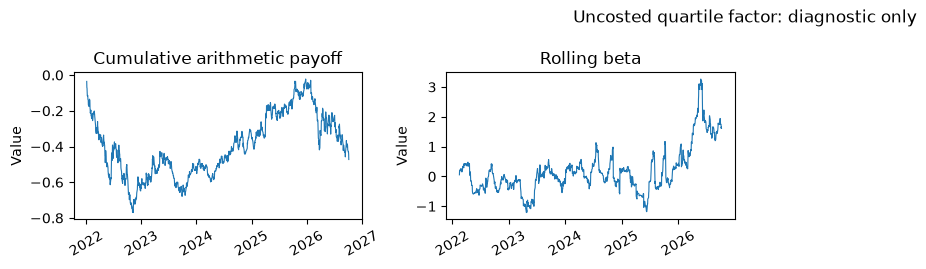

In [39]:
spread_betas = capm_spy.loc[ASSETS, "Beta"]
low_names = spread_betas.index[spread_betas <= spread_betas.quantile(.25)]
high_names = spread_betas.index[spread_betas >= spread_betas.quantile(.75)]
spread_evaluation = result["returns"].loc[result["portfolio_returns"].index, ASSETS]
low_high = pd.DataFrame({"Low-beta leg": spread_evaluation[low_names].mean(axis=1),
                         "High-beta leg": spread_evaluation[high_names].mean(axis=1)})
low_high["Low minus high"] = low_high.iloc[:, 0] - low_high.iloc[:, 1]
spread = low_high["Low minus high"]
spread_summary = pd.DataFrame({"Annual mean payoff": [spread.mean() * 252],
                               "Annual volatility": [spread.std() * np.sqrt(252)],
                               "Zero-cost payoff ratio": [spread.mean() / spread.std() * np.sqrt(252)]})
spread_membership = pd.DataFrame({"Training beta": spread_betas,
                                  "Leg": ["Low" if s in low_names else "High" if s in high_names else "Unused" for s in ASSETS]})
spread_rolling = rolling_market_model(spread.to_frame(), result["portfolio_returns"][BENCHMARK], best_window, annual_rf=0)
display(spread_membership)
display(spread_summary)
diagnostic_tables.update(quartile_spread_membership=spread_membership, quartile_spread_returns=low_high,
                         quartile_spread_summary=spread_summary, quartile_spread_beta=spread_rolling["beta"])
show_panels(pd.concat([spread.cumsum().rename("Cumulative arithmetic payoff"),
                       spread_rolling["beta"].iloc[:, 0].rename("Rolling beta")], axis=1),
             "Uncosted quartile factor: diagnostic only", "quartile_spread", "Value")

### Calculation: Named macro series and descriptive normalization

In [40]:
def load_inflation(path=None):
    """Global annual CPI rates in percentage points, selected by Series Name."""
    path = Path(path) if path else DATA_DIR / 'Inflation-data.xlsx'
    raw = pd.read_excel(path, sheet_name='Aggregate', engine='openpyxl')
    if 'Series Name' not in raw:
        raise ValueError('Inflation Aggregate sheet requires Series Name.')
    selected = raw.loc[raw['Series Name'].isin(INFLATION_SERIES)]
    if len(selected) != 3 or selected['Series Name'].duplicated().any():
        raise ValueError('Inflation file must contain each global CPI series exactly once.')
    years = [c for c in raw if re.fullmatch(r'\d{4}', str(c))]
    if not years:
        raise ValueError('Inflation file has no annual observation columns.')
    result = selected.set_index('Series Name')[years].T.rename(columns=INFLATION_SERIES)
    result.index = pd.Index([int(y) for y in years], name='Year')
    result = result.apply(pd.to_numeric, errors='raise').sort_index()
    if np.isinf(result.to_numpy()).any():
        raise ValueError('Inflation contains infinite values.')
    result.attrs.update(unit='percent per year', sha256=file_sha256(path))
    return result


def load_liquidity(path=None):
    """BIS bank credit as percent of GDP, selected by its full economic key."""
    path = Path(path) if path else DATA_DIR / 'WS_GLI_csv_col.csv'
    raw = pd.read_csv(path, dtype=str)
    missing = set(BIS_SERIES) - set(raw.columns)
    if missing:
        raise ValueError(f'BIS file lacks series metadata: {sorted(missing)}')
    mask = pd.Series(True, index=raw.index)
    for key, value in BIS_SERIES.items():
        mask &= raw[key].str.strip().eq(value)
    selected = raw.loc[mask]
    if len(selected) != 1:
        raise ValueError(f'BIS economic key must match exactly one series, found {len(selected)}.')
    quarters = [c for c in raw if re.fullmatch(r'\d{4}-Q[1-4]', c)]
    if not quarters:
        raise ValueError('BIS file has no quarterly observation columns.')
    values = pd.to_numeric(selected.iloc[0][quarters], errors='raise')
    result = pd.Series(values.to_numpy(dtype=float),
                       index=pd.PeriodIndex(quarters, freq='Q'), name='Bank credit (% of GDP)').sort_index()
    if np.isinf(result.to_numpy()).any() or result.notna().sum() == 0:
        raise ValueError('BIS observations must contain finite data.')
    result.index.name = 'Quarter'
    result.attrs.update(unit='percent of GDP', series_key=BIS_SERIES, sha256=file_sha256(path))
    return result


def normalize_context(series):
    """Full-sample z scores for display only; never a point-in-time signal."""
    values = pd.Series(series, dtype=float).dropna()
    if len(values) < 2 or not np.isfinite(values).all() or values.std() <= 0:
        raise ValueError('Context normalization needs finite, nonconstant observations.')
    return (values - values.mean()) / values.std()

### D. Inflation, bank credit and standardized context

The supplied World Bank CPI and BIS bank-credit series retain their own units.
BIS is selected by the full economic metadata key, not row number 142. A second
chart restores the standardized credit illustration. Full-sample normalization
is descriptive and uses future observations relative to earlier chart dates;
it is not a signal. These macro snapshots have no release-date history and are
not used to manufacture historical trading views.

**Original input status:** these unchanged submission inputs are inactive by default. `RUN_ORIGINAL_CONTEXT=True` explicitly re-enables the historical illustration; this does not update its vintage.

In [41]:
inflation = liquidity = macro_chart = None
# ORIGINAL 2024 SUBMISSION macro inputs — explicit opt-in only.
if RUN_ORIGINAL_CONTEXT and DATA_MODE != "synthetic":
    inflation, liquidity = load_inflation(), load_liquidity()
    credit = liquidity.loc["1996Q1":].copy()
    credit.index = credit.index.to_timestamp(how="end")
    standardized_credit = normalize_context(credit)
    macro_chart, axes = plt.subplots(3, 1, figsize=(11, 9))
    inflation.loc[1996:2023].plot(ax=axes[0])
    axes[0].set(title="World Bank global headline inflation", ylabel="Annual inflation (%)")
    credit.plot(ax=axes[1], color="teal")
    axes[1].set(title="BIS global bank credit: selected series", ylabel="Credit (% of GDP)")
    axes[2].bar(standardized_credit.index, standardized_credit, width=60, color="teal")
    axes[2].axhline(0, color="gray", linewidth=.8)
    axes[2].set(title="Same credit series: full-sample normalization", ylabel="Standard deviations")
    macro_chart.tight_layout()
    diagnostic_tables.update(global_inflation=inflation, global_bank_credit=liquidity.to_frame(),
                             standardized_bank_credit=standardized_credit.to_frame())
    diagnostic_figures["macro_context"] = macro_chart
    plt.show()
    plt.close(macro_chart)
else:
    print("Original submission macro snapshots inactive: no updated macro input selected.")

Original submission macro snapshots inactive: no updated macro input selected.


### E. Optional market-price proxies and current provider metadata

Set `RUN_NETWORK_CONTEXT=True` to acquire the source's six equity indices, GLD,
10-year Treasury yield and VIX. These inputs were not supplied as frozen files;
the default therefore skips this section's network calls explicitly. Errors stop
acquisition rather than inventing history. Downloads are a **current provider
vintage** and will be saved with a UTC acquisition time and hash.

An equal-weight average of standardized equity-index levels measures relative
market-price context, not economic growth. Gold is not an inflation series;
Treasury yield is not a liquidity quantity. Chart labels reflect those distinctions.
Equity indices are aligned on common observed dates for this display only.
The normalization uses the full downloaded sample and does not enter the backtest.

The separate metadata table restores provider beta/AUM inspection with Yahoo's
`beta3Year` and `totalAssets` fields, plus a recent ^IRX quoted annual discount yield.
Missing fields remain missing. The source's hard-coded Kavout fund-name URL is
replaced by this symbol-specific adapter. Current fields are never substituted
into historical CAPM or cash-rate calculations. The ^IRX quotation is not silently
treated as an effective annual cash return.

In [42]:
network_provenance = {"enabled": bool(RUN_NETWORK_CONTEXT), "status": "not requested"}
if RUN_NETWORK_CONTEXT:
    import hashlib
    from datetime import datetime, timezone
    import yfinance as yf
    growth_indices = {"S&P 500": "^GSPC", "Nikkei 225": "^N225", "Hang Seng": "^HSI",
                      "Shanghai Composite": "000001.SS", "Euro Stoxx 50": "^STOXX50E", "Nifty 50": "^NSEI"}
    symbols = list(growth_indices.values()) + ["GLD", "^TNX", "^VIX"]
    context_raw = yf.download(symbols, start=NETWORK_CONTEXT_START, end=END_DATE,
                              auto_adjust=False, progress=False, threads=False, timeout=30,
                              multi_level_index=True)
    if context_raw.empty or "Close" not in context_raw:
        raise ValueError("Optional context download returned no closes.")
    context_prices = context_raw["Close"].reindex(columns=symbols)
    if (context_prices.notna().sum() < 2).any():
        raise ValueError("Optional context history is missing one or more requested series.")
    common_equities = context_prices[list(growth_indices.values())].dropna()
    if len(common_equities) < 24:
        raise ValueError("Insufficient common equity-index observations.")
    standardized_indices = common_equities.apply(normalize_context).rename(columns={v: k for k, v in growth_indices.items()})
    context_series = pd.concat([
        standardized_indices.mean(axis=1).rename("Standardized equity-index composite"),
        normalize_context(context_prices["GLD"]).rename("Gold ETF price: standardized"),
        normalize_context(context_prices["^TNX"]).rename("10-year Treasury yield: standardized"),
        normalize_context(context_prices["^VIX"]).rename("VIX level: standardized")], axis=1)
    diagnostic_tables.update(optional_market_closes=context_prices, optional_market_context=context_series,
                             optional_standardized_equity_indices=standardized_indices)
    show_panels(context_series, "Market-price context; full-sample normalization", "optional_market_context", "Standard deviations")
    metadata_rows = []
    for symbol in universe_prices:
        try:
            info = yf.Ticker(symbol).get_info()
            metadata_rows.append({"ETF": symbol, "Provider beta3Year": info.get("beta3Year", np.nan),
                                  "Provider totalAssets": info.get("totalAssets", np.nan), "Error": ""})
        except Exception as exc:
            metadata_rows.append({"ETF": symbol, "Provider beta3Year": np.nan,
                                  "Provider totalAssets": np.nan, "Error": type(exc).__name__})
    provider_metadata = pd.DataFrame(metadata_rows).set_index("ETF")
    provider_metadata["Initial-window SPY beta (different period)"] = capm_spy["Beta"]
    irx = yf.Ticker("^IRX").history(period="5d")
    if irx.empty or "Close" not in irx:
        raise ValueError("Recent ^IRX quote unavailable.")
    diagnostic_tables.update(optional_current_metadata=provider_metadata,
                             optional_recent_irx_quote=irx[["Close"]].rename(columns={"Close": "Annual discount yield quote (%)"}))
    network_provenance = {"enabled": True, "status": "downloaded", "downloaded_utc": datetime.now(timezone.utc).isoformat(),
                          "start": NETWORK_CONTEXT_START, "end_exclusive": END_DATE,
                          "context_prices_csv_sha256": hashlib.sha256(context_prices.to_csv().encode()).hexdigest(),
                          "metadata_period": "current provider snapshot; not historical", "auto_adjust": False}
    display(provider_metadata)
    display(diagnostic_tables["optional_recent_irx_quote"].tail(1))
else:
    print("Optional network context not requested. Enable RUN_NETWORK_CONTEXT to execute this section.")

Optional network context not requested. Enable RUN_NETWORK_CONTEXT to execute this section.


### F. Source-code reconciliation

All **127 code cells** in the supplied **213-cell notebook** have been reviewed.
Indices below are zero-based positions in that supplied file, including Markdown
cells. Repeated displays, variable reshaping and repeated versions of a formula
are consolidated into one maintained calculation. Known incorrect calculations
are replaced explicitly; their original bytes remain in the historical materials.
No original research topic is silently omitted. Network-only inputs are executable
in the optional appendix and do not run by default.

The notebook metadata records a SHA-256 for the supplied file and each code cell,
plus its destination cell IDs. All calculation definitions are included in the notebook; metadata also maps each definition to its tested callable counterpart. This mapping does not claim verbatim reproduction.

| Source cells | Topic | Destination cell IDs | Review decision |
| --- | --- | --- | --- |
| 5, 6, 7 | Setup and helpers | `imports`, `configuration` | Modern imports, numeric weights and labelled tables replace formatting-only helpers. |
| 10, 12, 14, 15 | Acquisition, cache and coverage | `prices`, `universe-diagnostics`, `network-context` | Frozen prices plus explicit Yahoo mode; optional metadata replaces the hard-coded scraper. |
| 19, 21, 22, 24, 25, 26, 27, 28, 38, 43, 44, 45, 81, 82, 83 | Return preparation and inspection | `universe-diagnostics`, `analysis` | Within-asset returns, gap rejection and outlier/coverage tables; repeated previews consolidated. |
| 30, 32, 34, 76, 80, 84, 85, 86, 87 | Beta, CAPM and expected-return comparison | `rolling-diagnostics`, `bl-details`, `network-context` | Matching market proxies and prior-window estimation; current metadata separate. |
| 37, 39, 40, 67, 69, 70 | Moments, covariance and correlation | `universe-diagnostics`, `bl-details` | Correct annual units and genuine correlation; selection remains declared retrospective. |
| 48, 49, 50, 51 | Rolling alpha/beta and window score | `rolling-diagnostics` | Compare conditional return residuals on common training dates, never betas versus returns. |
| 54, 55, 56, 57 | Performance, Sortino, growth and drawdown | `universe-diagnostics`, `bab-rolling` | Consistent period risk-free rate, downside denominator and initial capital. |
| 60, 63, 64, 73, 74 | AUM and capped weights | `aum-snapshot` | Snapshot-only appendix with repeated cap enforcement; no historical AUM claim. |
| 78, 116, 117, 119, 121, 123, 127, 128, 129, 130, 131, 132, 137, 139 | BL prior, P/Q/Omega and covariance | `bl-details` | View-scaled uncertainty and linear solves; redundant formula checks consolidated. |
| 89, 90, 91, 93, 95, 96, 134, 135, 142, 175 | Return-vector and risk-aversion allocations | `risk-aversion` | Covariance-aware optimization with cash replaces normalized returns and arbitrary weight division. |
| 100, 114 | Equity-index, gold, yield and VIX context | `network-context`, `macro-context` | Optional acquisition with honest proxy labels; no inputs fabricated. |
| 103, 104, 105, 106, 108, 109, 110, 112, 113 | Inflation and BIS credit | `macro-context` | Named/economic-key series selection; retain original units and standardized display. |
| 146, 147, 148, 150, 151, 153, 154, 155, 163, 164, 165, 166, 168, 169, 170, 171, 172 | Core objectives and comparison plots | `analysis`, `weights`, `metrics`, `charts`, `bab-rolling` | Actual variance, Sharpe and tracking objectives with consistent annual metrics; no relabelled variance optimizer. |
| 157, 158, 160 | Higher-order moments and utility | `higher-moments`, `analysis` | Raw central tensors checked against the optimizer own portfolio; standardized pair slices are descriptive. |
| 178, 179, 180, 181, 182, 183, 184, 185 | Five-factor data, regression and plots | `factor-analysis`, `factor-fit` | Monthly compounding and decimal factors; full five-factor fitted values; repeated previews consolidated. |
| 187, 189, 191, 193, 194, 195 | Factor-threshold heuristic | `factor-tilt-experiment` | Appendix sensitivity with capped weights and correctly annualized monthly calibration metrics. |
| 198, 199, 201, 202 | Quartile beta spread and rolling exposures | `beta-spread`, `bab-rolling` | Separate uncosted factor proxy and net beta-neutral strategy diagnostics. |
| 206, 207, 208, 209 | Kelly weights, fractions and wealth | `kelly-comparison` | Cash-aware constrained full Kelly then scaling; dated net simple-return ledger. |

### Calculation: Export the dated research outputs and assumptions

In [43]:
def save_run(result, provenance, annual_rf, max_weight, parent='outputs'):
    """Save each run separately and carry the data-mode label into every result."""
    parent = Path(parent)
    parent.mkdir(parents=True, exist_ok=True)
    name = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    target = parent / f'{provenance["mode"]}_{name}'
    target.mkdir(exist_ok=False)
    for key in ['weights', 'weight_history', 'turnover', 'trading', 'historical',
                'model', 'portfolio_returns', 'covariance', 'views', 'bab_diagnostics']:
        table = result[key].copy()
        table.insert(0, 'Data source', provenance['label'])
        table.to_csv(target / f'{key}.csv')
    expected_returns = pd.DataFrame({'Prior annual excess return': result['prior'],
                                     'BL posterior annual excess return': result['posterior']})
    expected_returns.insert(0, 'Data source', provenance['label'])
    expected_returns.to_csv(target / 'black_litterman_returns.csv')
    metadata = {**provenance, 'annual_risk_free_assumption': annual_rf,
                'max_asset_weight': max_weight, 'return_rows_used': len(result['returns']),
                'training_days_before_first_evaluation': result['training_days'],
                'evaluation_start': str(result['evaluation_start'].date()),
                'evaluation_end': str(result['evaluation_end'].date()),
                'rebalance_rule': 'first available observation of each calendar month',
                'transaction_cost_bps_per_one_way_turnover': result['transaction_cost_bps'],
                'annual_short_borrow_bps': result['annual_short_borrow_bps'],
                'kelly_fraction': result['kelly_fraction'],
                'kelly_definition': 'fraction times constrained full-Kelly risky weights; cash allowed; cap before scaling',
                'borrow_accounting': 'daily short charges debited from cash; weights normalized by after-borrow NAV',
                'missing_price_policy': 'trim common endpoints; reject internal missing prices; no inferred exchange calendar',
                'bab_gross_limit': result['bab_gross_limit'],
                'portfolio_methods': list(result['weights'].columns),
                'universe_selection': 'fixed eight ETFs selected retrospectively in the 2024 study',
                'views_as_of': result['views_as_of'],
                'active_view_count': len(result['views']),
                'evaluation': ('retrospective scenario with chronological walk-forward parameter fitting; '
                               'the 2024-selected universe is applied to earlier dates; '
                               'only explicitly supplied views are active; '
                               'not a point-in-time out-of-sample strategy test')}
    (target / 'run_info.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    return target

## Save the complete research outputs

Each run creates a new timestamped folder under `outputs/`. Besides the main
portfolio results, it saves all restored diagnostic tables and figures, the raw
third/fourth-order moment tensors with asset ordering, source-cell reconciliation,
and optional acquisition status. These supplemental results are labelled as
diagnostics or sensitivity experiments in their notebook sections.

In [44]:
output_folder = save_run(result, provenance, ANNUAL_RISK_FREE_RATE, MAX_WEIGHT)
if factor_results is not None:
    factor_results.to_csv(output_folder / "factor_regression.csv")
if universe_factor_results is not None:
    universe_factor_results.to_csv(output_folder / "universe_factor_regression.csv")
for label, table in diagnostic_tables.items():
    table.to_csv(output_folder / f"{label}.csv")
for label, figure in diagnostic_figures.items():
    figure.savefig(output_folder / f"{label}.png", dpi=120, bbox_inches="tight")
np.savez_compressed(output_folder / "higher_moment_tensors.npz",
                    third=moment_diagnostics["third"], fourth=moment_diagnostics["fourth"], assets=np.array(ASSETS))
weight_chart.savefig(output_folder / "allocations.png", dpi=150, bbox_inches="tight")
growth_chart.savefig(output_folder / "growth.png", dpi=150, bbox_inches="tight")
import json
import nbformat
notebook_source = nbformat.read("portfolio_construction.ipynb", as_version=4)
supplementary_info = {
    "rolling_window_candidates": list(ROLLING_WINDOWS), "selected_window": best_window,
    "risk_aversions": list(RISK_AVERSIONS), "kelly_comparison_fractions": list(KELLY_COMPARISON_FRACTIONS),
    "network_context": network_provenance, "source_reconciliation": dict(notebook_source.metadata.source_reconciliation),
    "diagnostic_tables": list(diagnostic_tables), "diagnostic_figures": list(diagnostic_figures),
    "interpretation": "Core diagnostics and explicitly labelled supplementary experiments; see notebook sections.",
}
(output_folder / "supplementary_info.json").write_text(json.dumps(supplementary_info, indent=2), encoding="utf-8")
print("RUN COMPLETE")
print("Data:", provenance["label"])
print("Saved results:", output_folder.as_posix())

RUN COMPLETE
Data: YAHOO FINANCE - adjusted historical prices, downloaded now
Saved results: outputs/yahoo_20261009T024315_213818Z
